# 10. app.py 핵심 로직 검증

**목적**: app.py에서 사용하는 적정 요금 구간 로직과 호스트 등급 분류 기준을 데이터로 검증

---

## 핵심 로직 요약 (app.py 확인)

| 항목 | app.py 실제 구현 |
|------|-------------------|
| 벤치마크 모수 | `active_df` (refined_status=Active & operation_status=Operating) |
| 그룹 기준 | district × room_type |
| `b_adr` | `np.percentile(ttm_avg_rate, 50)` — **중위값 (median)** |
| `b_adr_p25` | `np.percentile(ttm_avg_rate, 25)` |
| `b_adr_p75` | `np.percentile(ttm_avg_rate, 75)` |
| 신규 구간 | `p25 × 0.85` ~ `p25` |
| 안정 구간 | `p25` ~ `median` |
| 프리미엄 구간 | `median` ~ `p75` |



In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import matplotlib.patches as mpatches
from scipy import stats
from scipy.stats import f_oneway, kruskal
import statsmodels.api as sm
import warnings
warnings.filterwarnings('ignore')

# ── 한글 폰트
import platform
system = platform.system()
if system == 'Windows':
    plt.rcParams['font.family'] = 'Malgun Gothic'
elif system == 'Darwin':
    plt.rcParams['font.family'] = 'AppleGothic'
else:
    plt.rcParams['font.family'] = 'NanumGothic'
plt.rcParams['axes.unicode_minus'] = False

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

print('라이브러리 로드 완료')

라이브러리 로드 완료


In [2]:
# ── 데이터 로드
df = pd.read_csv('../data/raw/seoul_airbnb_cleaned.csv')
print(f'전체: {len(df):,}행 × {df.shape[1]}열')

# app.py와 동일한 active_df 정의
active_df = df[
    (df['refined_status'] == 'Active') &
    (df['operation_status'] == 'Operating')
].copy()
print(f'Active+Operating (벤치마크 모수): {len(active_df):,}행')
print(f'Dormant 비율: {1 - len(active_df)/len(df):.1%}')

# 주요 컬럼 확인
key_cols = ['district', 'room_type', 'ttm_avg_rate', 'ttm_revpar', 'ttm_occupancy',
            'superhost', 'num_reviews', 'rating_overall']
print('\n결측치 (active_df):')
print(active_df[key_cols].isnull().sum())

전체: 32,061행 × 42열
Active+Operating (벤치마크 모수): 14,399행
Dormant 비율: 55.1%

결측치 (active_df):
district          0
room_type         0
ttm_avg_rate      0
ttm_revpar        0
ttm_occupancy     0
superhost         0
num_reviews       0
rating_overall    0
dtype: int64


---
# 1단계: app.py 적정 요금 로직 재현 및 검증

## 1-1. app.py 로직 함수 재현

In [3]:
# ── app.py bench_val() 동일 구현
def bench_val(bench, col, default, pct=50):
    """app.py의 bench_val() 함수를 그대로 재현"""
    if len(bench) > 0 and col in bench.columns:
        vals = bench[col].dropna()
        if len(vals) > 0:
            return float(np.percentile(vals, pct))
    return default

def get_bench(district, room_type):
    """app.py의 get_bench() 함수를 그대로 재현"""
    return active_df[
        (active_df['district'] == district) &
        (active_df['room_type'] == room_type)
    ]

# ── 자치구 × 숙소유형별 요금 구간 계산
groups = active_df.groupby(['district', 'room_type'])

price_stats = groups['ttm_avg_rate'].agg(
    count='count',
    mean='mean',
    median='median',
    p25=lambda x: np.percentile(x.dropna(), 25),
    p75=lambda x: np.percentile(x.dropna(), 75),
    std='std'
).reset_index()

# app.py 용어로 매핑: b_adr = median (p50)
price_stats['b_adr_p25']    = price_stats['p25']    # b_adr_p25
price_stats['b_adr_median'] = price_stats['median'] # b_adr (실제 중위값)
price_stats['b_adr_mean']   = price_stats['mean']   # 실제 평균 (비교용)
price_stats['b_adr_p75']    = price_stats['p75']    # b_adr_p75

# 요금 구간 경계
price_stats['tier_new_min']  = price_stats['b_adr_p25'] * 0.85
price_stats['tier_new_max']  = price_stats['b_adr_p25']
price_stats['tier_stab_min'] = price_stats['b_adr_p25']
price_stats['tier_stab_max'] = price_stats['b_adr_median']
price_stats['tier_prem_min'] = price_stats['b_adr_median']
price_stats['tier_prem_max'] = price_stats['b_adr_p75']

# IQR 및 구간 폭
price_stats['iqr']            = price_stats['p75'] - price_stats['p25']
price_stats['new_width']      = price_stats['tier_new_max'] - price_stats['tier_new_min']
price_stats['stable_width']   = price_stats['tier_stab_max'] - price_stats['tier_stab_min']
price_stats['premium_width']  = price_stats['tier_prem_max'] - price_stats['tier_prem_min']

print(f'자치구 × 숙소유형 그룹 수: {len(price_stats)}')
price_stats[['district','room_type','count','p25','median','mean','p75','iqr']].sort_values(
    'count', ascending=False).head(20)

자치구 × 숙소유형 그룹 수: 69


,district,room_type,count,p25,median,mean,p75,iqr
40,Mapo-gu,entire_home,2536,104396.191815,141517.532762,165703.975987,191845.826878,87449.635063
66,Yongsan-gu,entire_home,1093,90980.709498,129257.413461,146880.632337,177394.414267,86413.704770
34,Jung-gu,entire_home,1044,112704.801271,151457.873544,171518.163157,192518.327060,79813.525788
14,Gangnam-gu,entire_home,1018,84775.618146,101184.860042,135992.633947,140110.769144,55335.150997
30,Jongno-gu,entire_home,855,91399.539504,132520.495059,197033.407453,261890.469733,170490.930229
42,Mapo-gu,private_room,652,40836.397205,59907.812139,72158.635078,92733.531373,51897.134168
36,Jung-gu,private_room,643,60169.523897,97674.806990,135921.968276,162544.501266,102374.977369
32,Jongno-gu,private_room,517,55033.605678,77472.463570,103717.544473,114278.581441,59244.975763
46,Seocho-gu,entire_home,496,83714.602595,105874.101051,127644.195795,142236.012015,58521.409421
49,Seodaemun-gu,entire_home,414,71870.536610,107447.156495,138961.332424,160681.718810,88811.182200


In [4]:
# ── 중위값 vs 평균 괴리 분석 (app.py 로직의 실제 효과)
price_stats['median_vs_mean_pct'] = (price_stats['median'] - price_stats['mean']) / price_stats['mean'] * 100

print('=== 중위값(b_adr)과 평균의 괴리 분석 ===')
print(f'median vs mean 차이 (%):')
print(price_stats['median_vs_mean_pct'].describe().round(1))
print(f'\n전체 그룹 중 median < mean인 비율: {(price_stats["median"] < price_stats["mean"]).mean():.1%}')
print('→ 오른쪽 꼬리(고가 이상치) 존재 시 median이 더 보수적 기준')

=== 중위값(b_adr)과 평균의 괴리 분석 ===
median vs mean 차이 (%):
count    69.0
mean    -15.6
std      13.2
min     -75.5
25%     -22.7
50%     -14.6
75%      -7.8
max       5.9
Name: median_vs_mean_pct, dtype: float64

전체 그룹 중 median < mean인 비율: 84.1%
→ 오른쪽 꼬리(고가 이상치) 존재 시 median이 더 보수적 기준


In [5]:
# ── 전체 숙소(active_df)에 대해 구간 레이블 부여

# 그룹별 구간 정보를 merge
active_labeled = active_df.merge(
    price_stats[['district','room_type','tier_new_min','tier_new_max',
                 'tier_stab_min','tier_stab_max','tier_prem_min','tier_prem_max']],
    on=['district','room_type'], how='left'
)

def assign_price_tier(row):
    adr = row['ttm_avg_rate']
    if pd.isna(adr) or pd.isna(row['tier_new_min']):
        return '분류불가'
    if adr < row['tier_new_min']:
        return '구간미만'
    elif adr <= row['tier_new_max']:
        return '신규'
    elif adr <= row['tier_stab_max']:
        return '안정'
    elif adr <= row['tier_prem_max']:
        return '프리미엄'
    else:
        return '구간초과'

active_labeled['price_tier'] = active_labeled.apply(assign_price_tier, axis=1)

tier_counts = active_labeled['price_tier'].value_counts()
tier_pct    = active_labeled['price_tier'].value_counts(normalize=True) * 100

print('=== 전체 active_df 구간별 분포 ===')
summary = pd.DataFrame({'count': tier_counts, 'pct(%)': tier_pct.round(1)})
print(summary)
print(f'\n추천 구간 내 비율 (신규+안정+프리미엄): '
      f'{tier_pct[["신규","안정","프리미엄"]].sum():.1f}%')
print(f'구간 미만: {tier_pct.get("구간미만", 0):.1f}%')
print(f'구간 초과: {tier_pct.get("구간초과", 0):.1f}%')

=== 전체 active_df 구간별 분포 ===
            count  pct(%)
price_tier               
구간초과         3602    25.0
안정           3592    24.9
프리미엄         3577    24.8
구간미만         2026    14.1
신규           1602    11.1

추천 구간 내 비율 (신규+안정+프리미엄): 60.9%
구간 미만: 14.1%
구간 초과: 25.0%


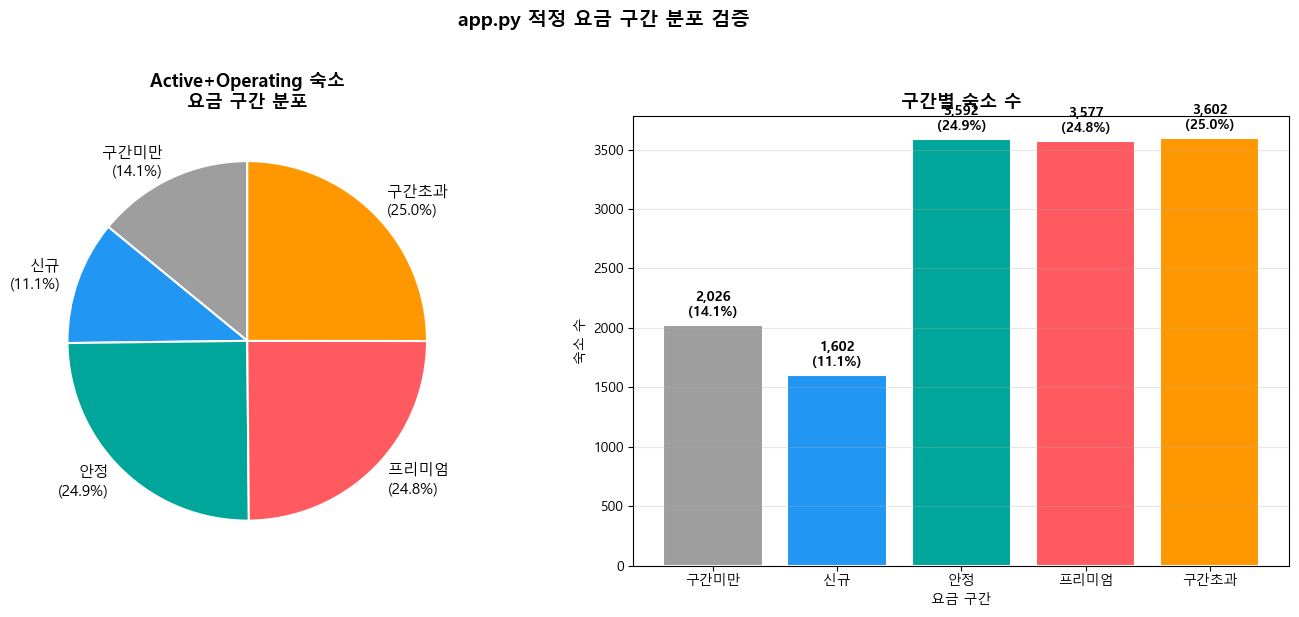

저장: reports/fig_10_price_tier_distribution.png


In [6]:
# ── 그림 1: 구간별 분포 파이차트
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

tier_order  = ['구간미만', '신규', '안정', '프리미엄', '구간초과', '분류불가']
tier_colors = {'구간미만': '#9E9E9E', '신규': '#2196F3', '안정': '#00A699',
               '프리미엄': '#FF5A5F', '구간초과': '#FF9800', '분류불가': '#E0E0E0'}

plot_data = tier_counts.reindex([t for t in tier_order if t in tier_counts.index])
colors    = [tier_colors[t] for t in plot_data.index]

# 파이
axes[0].pie(
    plot_data.values,
    labels=[f'{t}\n({v/len(active_labeled)*100:.1f}%)' for t, v in plot_data.items()],
    colors=colors, startangle=90,
    wedgeprops={'linewidth': 1.5, 'edgecolor': 'white'},
    textprops={'fontsize': 11}
)
axes[0].set_title('Active+Operating 숙소\n요금 구간 분포', fontsize=13, fontweight='bold')

# 바차트
bars = axes[1].bar(plot_data.index, plot_data.values, color=colors, edgecolor='white', linewidth=1.5)
for bar, (tier, val) in zip(bars, plot_data.items()):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 50,
                 f'{val:,}\n({val/len(active_labeled)*100:.1f}%)',
                 ha='center', va='bottom', fontsize=10, fontweight='bold')
axes[1].set_title('구간별 숙소 수', fontsize=13, fontweight='bold')
axes[1].set_ylabel('숙소 수')
axes[1].set_xlabel('요금 구간')
axes[1].grid(axis='y', alpha=0.3)

plt.suptitle('app.py 적정 요금 구간 분포 검증', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('../reports/fig_10_price_tier_distribution.png', dpi=100, bbox_inches='tight')
plt.show()
print('저장: reports/fig_10_price_tier_distribution.png')

In [7]:
# ── 구간별 평균 RevPAR & Occupancy
valid_tiers = active_labeled[active_labeled['price_tier'].isin(['구간미만','신규','안정','프리미엄','구간초과'])]

tier_kpi = valid_tiers.groupby('price_tier').agg(
    n                = ('ttm_revpar', 'count'),
    mean_revpar      = ('ttm_revpar', 'mean'),
    median_revpar    = ('ttm_revpar', 'median'),
    mean_occupancy   = ('ttm_occupancy', 'mean'),
    median_occupancy = ('ttm_occupancy', 'median'),
    mean_adr         = ('ttm_avg_rate', 'mean'),
).round(0)

# 구간 순서
tier_display_order = ['구간미만', '신규', '안정', '프리미엄', '구간초과']
tier_kpi = tier_kpi.reindex([t for t in tier_display_order if t in tier_kpi.index])

print('=== 요금 구간별 평균 KPI ===')
print(tier_kpi.to_string())

=== 요금 구간별 평균 KPI ===
               n  mean_revpar  median_revpar  mean_occupancy  median_occupancy  mean_adr
price_tier                                                                              
구간미만        2026      28074.0        24475.0             1.0               1.0   52149.0
신규          1602      37927.0        35315.0             1.0               1.0   70107.0
안정          3592      48848.0        45940.0             1.0               1.0   89742.0
프리미엄        3577      62936.0        57155.0             0.0               1.0  124257.0
구간초과        3602     109803.0        83319.0             0.0               0.0  236767.0


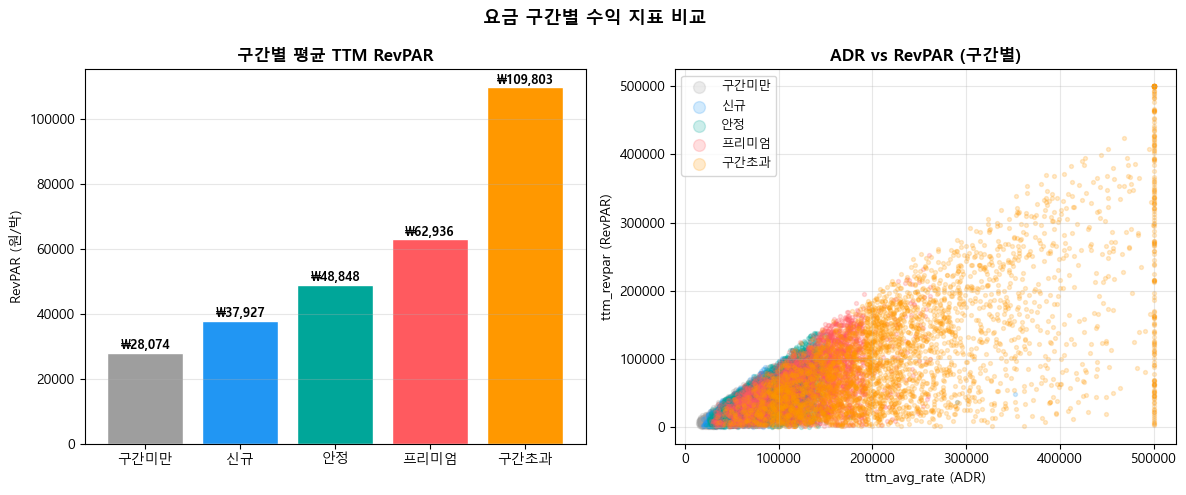

In [8]:
# ── 그림 2: 구간별 RevPAR & Occupancy 비교
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

plot_tiers  = [t for t in tier_display_order if t in tier_kpi.index]
plot_colors = [tier_colors[t] for t in plot_tiers]

# 1️RevPAR 막대그래프
bars = axes[0].bar(
    plot_tiers,
    tier_kpi.loc[plot_tiers, 'mean_revpar'],
    color=plot_colors,
    edgecolor='white'
)

for bar, val in zip(bars, tier_kpi.loc[plot_tiers, 'mean_revpar']):
    axes[0].text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height() + 200,
        f'₩{int(val):,}',
        ha='center',
        va='bottom',
        fontsize=9,
        fontweight='bold'
    )

axes[0].set_title('구간별 평균 TTM RevPAR', fontsize=12, fontweight='bold')
axes[0].set_ylabel('RevPAR (원/박)')
axes[0].grid(axis='y', alpha=0.3)


# ADR vs RevPAR scatter
for tier in plot_tiers:
    subset = valid_tiers[valid_tiers['price_tier'] == tier]
    axes[1].scatter(
        subset['ttm_avg_rate'].clip(0, 500000),
        subset['ttm_revpar'].clip(0, 500000),
        c=tier_colors[tier],
        alpha=0.2,
        s=8,
        label=tier
    )

axes[1].set_xlabel('ttm_avg_rate (ADR)')
axes[1].set_ylabel('ttm_revpar (RevPAR)')
axes[1].set_title('ADR vs RevPAR (구간별)', fontsize=12, fontweight='bold')
axes[1].legend(fontsize=9, markerscale=3)
axes[1].grid(alpha=0.3)

plt.suptitle('요금 구간별 수익 지표 비교', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('../reports/fig_10_tier_kpi_comparison.png', dpi=100, bbox_inches='tight')
plt.show()

In [9]:
# ── ANOVA: 구간 간 RevPAR 평균 차이 검정
from scipy.stats import f_oneway, kruskal

tier_revpar_groups = [
    valid_tiers[valid_tiers['price_tier'] == t]['ttm_revpar'].dropna().values
    for t in tier_display_order if t in valid_tiers['price_tier'].unique()
]
used_tiers = [t for t in tier_display_order if t in valid_tiers['price_tier'].unique()]

f_stat, p_val_anova = f_oneway(*tier_revpar_groups)
h_stat, p_val_kruskal = kruskal(*tier_revpar_groups)

# Eta-squared (효과크기)
grand_mean = valid_tiers['ttm_revpar'].dropna().mean()
ss_between = sum(
    len(g) * (g.mean() - grand_mean)**2 for g in tier_revpar_groups
)
ss_total = valid_tiers['ttm_revpar'].dropna().apply(lambda x: (x - grand_mean)**2).sum()
eta_sq = ss_between / ss_total

print('=== 요금 구간 간 RevPAR 차이 검정 ===')
print(f'One-way ANOVA: F={f_stat:.2f}, p={p_val_anova:.4e}')
print(f'Kruskal-Wallis: H={h_stat:.2f}, p={p_val_kruskal:.4e}')
print(f'효과크기 Eta²={eta_sq:.4f}  ({'큰 효과' if eta_sq > 0.14 else '중간 효과' if eta_sq > 0.06 else '작은 효과'})')
print()
if p_val_anova < 0.001:
    print('✅ 요금 구간 간 RevPAR 차이는 통계적으로 매우 유의함 (p<0.001)')
else:
    print(f'⚠️ p={p_val_anova:.4f}')

=== 요금 구간 간 RevPAR 차이 검정 ===
One-way ANOVA: F=946.87, p=0.0000e+00
Kruskal-Wallis: H=2587.30, p=0.0000e+00
효과크기 Eta²=0.2083  (큰 효과)

✅ 요금 구간 간 RevPAR 차이는 통계적으로 매우 유의함 (p<0.001)


In [10]:
# ── 사후 검정: Tukey HSD (구간 간 쌍별 비교)
from statsmodels.stats.multicomp import pairwise_tukeyhsd

tukey_data   = valid_tiers[valid_tiers['ttm_revpar'].notna()][['ttm_revpar','price_tier']]
tukey_result = pairwise_tukeyhsd(
    tukey_data['ttm_revpar'],
    tukey_data['price_tier'],
    alpha=0.05
)
print('=== Tukey HSD 사후 검정 ===')
print(tukey_result)

=== Tukey HSD 사후 검정 ===
     Multiple Comparison of Means - Tukey HSD, FWER=0.05      
group1 group2   meandiff  p-adj    lower       upper    reject
--------------------------------------------------------------
  구간미만   구간초과   81729.142   0.0  77449.5954  86008.6886   True
  구간미만     신규     9853.66   0.0   4701.4334  15005.8866   True
  구간미만     안정  20774.7543   0.0  16493.0637  25056.4448   True
  구간미만   프리미엄  34862.0978   0.0   30577.171  39147.0247   True
  구간초과     신규  -71875.482   0.0 -76503.3166 -67247.6474   True
  구간초과     안정 -60954.3878   0.0 -64588.1582 -57320.6173   True
  구간초과   프리미엄 -46867.0442   0.0 -50504.6275 -43229.4609   True
    신규     안정  10921.0942   0.0    6291.277  15550.9115   True
    신규   프리미엄  25008.4378   0.0  20375.6275  29641.2482   True
    안정   프리미엄  14087.3436   0.0  10447.2383  17727.4489   True
--------------------------------------------------------------


In [11]:
# ── 0.85 계수 검증: 신규 구간 하한의 타당성 분석
print('=== 0.85 계수 타당성 분석 ===')
print()

# p25 이하 구간을 세분화하여 비교
below_p25 = active_labeled[active_labeled['price_tier'].isin(['구간미만', '신규'])].copy()
below_p25['sub_tier'] = np.where(
    below_p25['price_tier'] == '구간미만', '신규 구간 미만 (< 0.85×p25)', '신규 구간 (0.85×p25 ~ p25)'
)

sub_tier_kpi = below_p25.groupby('sub_tier').agg(
    n              = ('ttm_revpar', 'count'),
    mean_revpar    = ('ttm_revpar', 'mean'),
    median_revpar  = ('ttm_revpar', 'median'),
    mean_occ       = ('ttm_occupancy', 'mean'),
    mean_adr       = ('ttm_avg_rate', 'mean'),
).round(0)
print(sub_tier_kpi.to_string())

# RevPAR 차이가 의미있는지 t-test
g1 = below_p25[below_p25['price_tier'] == '구간미만']['ttm_revpar'].dropna()
g2 = below_p25[below_p25['price_tier'] == '신규']['ttm_revpar'].dropna()
if len(g1) > 0 and len(g2) > 0:
    t_stat, p_t = stats.ttest_ind(g1, g2)
    print(f'\n0.85×p25 미만 vs 신규구간 RevPAR: t={t_stat:.2f}, p={p_t:.4f}')

print()
# 다양한 계수 시나리오 비교
print('계수별 신규 구간 하한 비율 비교 (active_df 기준):')
for coef in [0.75, 0.80, 0.85, 0.90, 0.95]:
    below_count = 0
    for _, row in active_labeled.iterrows():
        if pd.notna(row['ttm_avg_rate']) and pd.notna(row['tier_new_max']):
            if row['ttm_avg_rate'] < row['tier_new_max'] * coef:
                below_count += 1
    print(f'  계수 {coef:.2f} → 구간 미만 비율: {below_count/len(active_labeled):.1%}')

=== 0.85 계수 타당성 분석 ===

                           n  mean_revpar  median_revpar  mean_occ  mean_adr
sub_tier                                                                    
신규 구간 (0.85×p25 ~ p25)  1602      37927.0        35315.0       1.0   70107.0
신규 구간 미만 (< 0.85×p25)   2026      28074.0        24475.0       1.0   52149.0

0.85×p25 미만 vs 신규구간 RevPAR: t=-13.88, p=0.0000

계수별 신규 구간 하한 비율 비교 (active_df 기준):


  계수 0.75 → 구간 미만 비율: 8.8%


  계수 0.80 → 구간 미만 비율: 11.4%


  계수 0.85 → 구간 미만 비율: 14.1%


  계수 0.90 → 구간 미만 비율: 17.3%


  계수 0.95 → 구간 미만 비율: 20.8%


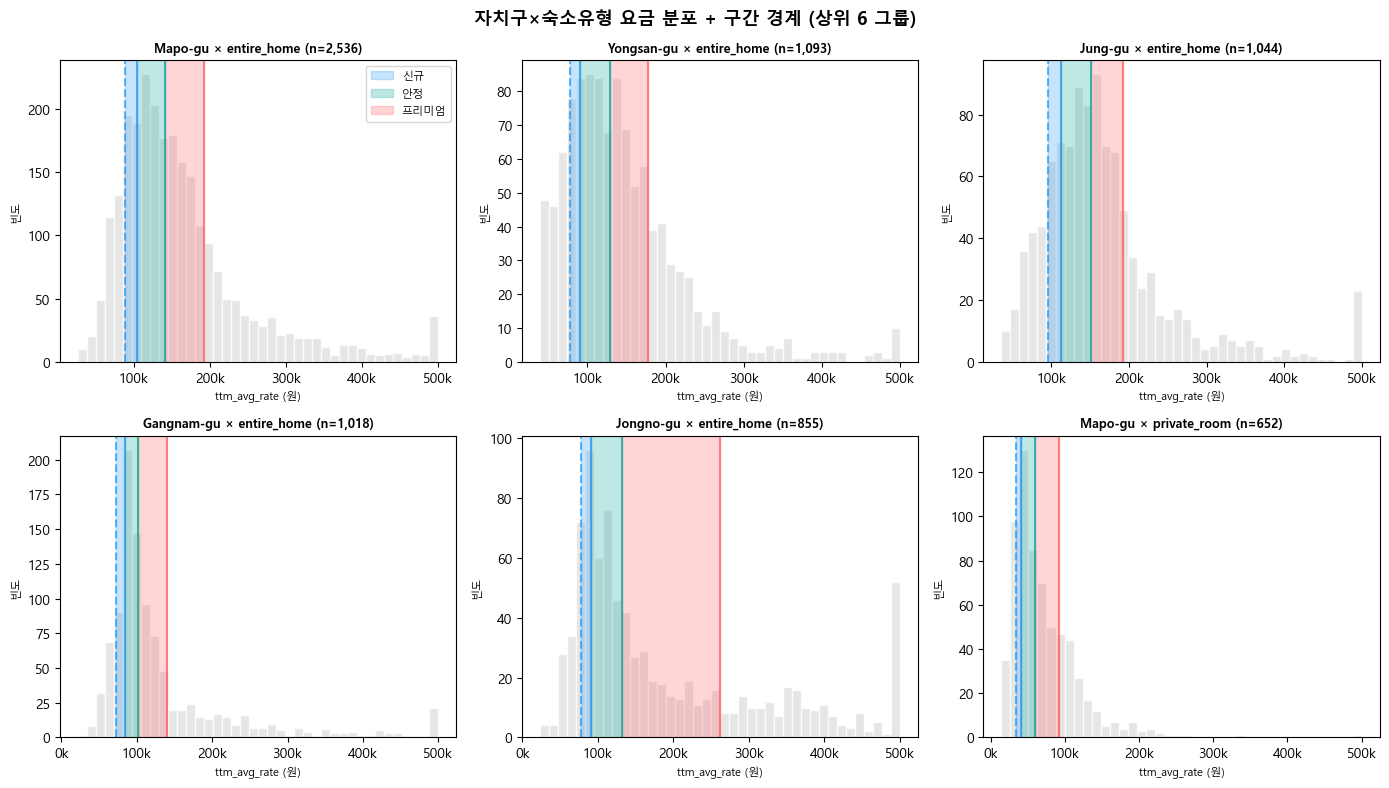

In [12]:
# ── 그림 3: ttm_avg_rate 전체 분포 + 구간 경계선
# 대표 그룹: 마포구 × 집 전체 (largest group)
top_groups = price_stats.nlargest(6, 'count')[['district','room_type','count',
                                                'tier_new_min','tier_new_max',
                                                'tier_stab_min','tier_stab_max',
                                                'tier_prem_min','tier_prem_max']]

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
axes = axes.flatten()

for idx, (_, row) in enumerate(top_groups.iterrows()):
    ax = axes[idx]
    subset = active_df[
        (active_df['district'] == row['district']) &
        (active_df['room_type'] == row['room_type'])
    ]['ttm_avg_rate'].dropna()
    
    subset_clipped = subset.clip(0, 500000)
    ax.hist(subset_clipped, bins=40, color='#E0E0E0', edgecolor='white', alpha=0.8)
    
    # 구간 색상 영역
    ymax = ax.get_ylim()[1] if ax.get_ylim()[1] > 0 else 10
    ax.axvspan(row['tier_new_min'], row['tier_new_max'],
               alpha=0.25, color='#2196F3', label='신규')
    ax.axvspan(row['tier_stab_min'], row['tier_stab_max'],
               alpha=0.25, color='#00A699', label='안정')
    ax.axvspan(row['tier_prem_min'], row['tier_prem_max'],
               alpha=0.25, color='#FF5A5F', label='프리미엄')
    
    ax.axvline(row['tier_new_min'],  color='#2196F3', lw=1.5, ls='--', alpha=0.7)
    ax.axvline(row['tier_new_max'],  color='#2196F3', lw=1.5, alpha=0.7)
    ax.axvline(row['tier_stab_max'], color='#00A699', lw=1.5, alpha=0.7)
    ax.axvline(row['tier_prem_max'], color='#FF5A5F', lw=1.5, alpha=0.7)
    
    ax.set_title(f"{row['district']} × {row['room_type']} (n={row['count']:,})",
                 fontsize=9, fontweight='bold')
    ax.set_xlabel('ttm_avg_rate (원)', fontsize=8)
    ax.set_ylabel('빈도', fontsize=8)
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x/1000:.0f}k'))
    if idx == 0:
        ax.legend(fontsize=8, loc='upper right')

plt.suptitle('자치구×숙소유형 요금 분포 + 구간 경계 (상위 6 그룹)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('../reports/fig_10_rate_distribution_with_tiers.png', dpi=100, bbox_inches='tight')
plt.show()

In [13]:
# ── 구간 폭 분석: 신규 구간이 안정/프리미엄 대비 좁은가?
print('=== 구간 폭 분석 ===')
width_summary = price_stats[['room_type','new_width','stable_width','premium_width','iqr']].groupby('room_type').mean().round(0)
width_summary['new_pct_of_iqr']    = (width_summary['new_width'] / width_summary['iqr'] * 100).round(1)
width_summary['stable_pct_of_iqr'] = (width_summary['stable_width'] / width_summary['iqr'] * 100).round(1)
print(width_summary.to_string())
print()
print('신규 구간 폭 = p25 × 0.15 (p25의 15%)')
print('안정 구간 폭 = median - p25 (interquartile 하반)')
print('프리미엄 구간 폭 = p75 - median (interquartile 상반)')

# 전체 평균
print(f'\n전체 그룹 평균 구간 폭:')
print(f'  신규:     ₩{price_stats["new_width"].mean():,.0f}')
print(f'  안정:     ₩{price_stats["stable_width"].mean():,.0f}')
print(f'  프리미엄: ₩{price_stats["premium_width"].mean():,.0f}')

=== 구간 폭 분석 ===
              new_width  stable_width  premium_width      iqr  new_pct_of_iqr  stable_pct_of_iqr
room_type                                                                                       
entire_home     10814.0       24063.0        36586.0  60650.0            17.8               39.7
hotel_room      13567.0       26448.0        16539.0  42986.0            31.6               61.5
private_room     5784.0       15467.0        26840.0  42307.0            13.7               36.6
shared_room     12208.0        2361.0         6502.0   8863.0           137.7               26.6

신규 구간 폭 = p25 × 0.15 (p25의 15%)
안정 구간 폭 = median - p25 (interquartile 하반)
프리미엄 구간 폭 = p75 - median (interquartile 상반)

전체 그룹 평균 구간 폭:
  신규:     ₩9,454
  안정:     ₩16,369
  프리미엄: ₩25,353


In [14]:
# ── 추가 검증: RevPAR vs ADR 상관관계 (구간별)
print('=== 구간별 ADR-RevPAR 상관관계 ===')
for tier in ['신규', '안정', '프리미엄']:
    sub = valid_tiers[valid_tiers['price_tier'] == tier][['ttm_avg_rate','ttm_revpar','ttm_occupancy']].dropna()
    if len(sub) > 10:
        r_adr_revpar, p1 = stats.pearsonr(sub['ttm_avg_rate'], sub['ttm_revpar'])
        r_occ_revpar, p2 = stats.pearsonr(sub['ttm_occupancy'], sub['ttm_revpar'])
        print(f'{tier:6s}: ADR↔RevPAR r={r_adr_revpar:.3f}(p={p1:.3f}), '
              f'Occ↔RevPAR r={r_occ_revpar:.3f}(p={p2:.3f}), n={len(sub):,}')

print()
print('→ 프리미엄 구간에서 ADR과 RevPAR의 상관이 강하다면 고요금 전략이 수익에 유리')
print('→ 신규 구간에서 예약률 기여가 크다면 저요금 전략의 RevPAR 보완 효과 확인 가능')

=== 구간별 ADR-RevPAR 상관관계 ===
신규    : ADR↔RevPAR r=0.628(p=0.000), Occ↔RevPAR r=0.843(p=0.000), n=1,602
안정    : ADR↔RevPAR r=0.676(p=0.000), Occ↔RevPAR r=0.817(p=0.000), n=3,592
프리미엄  : ADR↔RevPAR r=0.610(p=0.000), Occ↔RevPAR r=0.821(p=0.000), n=3,577

→ 프리미엄 구간에서 ADR과 RevPAR의 상관이 강하다면 고요금 전략이 수익에 유리
→ 신규 구간에서 예약률 기여가 크다면 저요금 전략의 RevPAR 보완 효과 확인 가능


---
# 2단계: app.py 호스트 등급 기준 검증

## 2-1. 등급 분류 재현

In [15]:
# ── app.py 호스트 등급 기준 그대로 구현
def classify_host_grade(row):
    """app.py step5()의 등급 분류 로직을 그대로 재현"""
    superhost   = bool(row['superhost'])
    rating      = row['rating_overall']
    num_reviews = row['num_reviews']
    
    if pd.isna(rating) or pd.isna(num_reviews):
        return '분류불가'
    
    if superhost and rating >= 4.8 and num_reviews >= 50:
        return '프리미엄'
    elif num_reviews >= 10 and rating >= 4.5:
        return '안정'
    else:
        return '신규'

active_labeled['host_grade'] = active_labeled.apply(classify_host_grade, axis=1)

grade_counts = active_labeled['host_grade'].value_counts()
grade_pct    = active_labeled['host_grade'].value_counts(normalize=True) * 100

print('=== 호스트 등급별 분포 ===')
grade_summary = pd.DataFrame({'count': grade_counts, 'pct(%)': grade_pct.round(1)})
print(grade_summary)

print(f'\n분류불가 제외 후 분석 진행')
print(f'  - superhost=True 비율: {active_labeled["superhost"].mean():.1%}')
print(f'  - 리뷰 >= 50 & 평점 >= 4.8 & superhost: {len(active_labeled[(active_labeled["superhost"]==True) & (active_labeled["rating_overall"]>=4.8) & (active_labeled["num_reviews"]>=50)]):,}')

=== 호스트 등급별 분포 ===
            count  pct(%)
host_grade               
안정           7834    54.4
신규           3441    23.9
프리미엄         3124    21.7

분류불가 제외 후 분석 진행
  - superhost=True 비율: 56.4%
  - 리뷰 >= 50 & 평점 >= 4.8 & superhost: 3,124


In [16]:
# ── 등급별 평균 KPI
grade_kpi = active_labeled[active_labeled['host_grade'] != '분류불가'].groupby('host_grade').agg(
    n                = ('ttm_revpar', 'count'),
    mean_revpar      = ('ttm_revpar', 'mean'),
    median_revpar    = ('ttm_revpar', 'median'),
    mean_adr         = ('ttm_avg_rate', 'mean'),
    median_adr       = ('ttm_avg_rate', 'median'),
    mean_occupancy   = ('ttm_occupancy', 'mean'),
    median_occupancy = ('ttm_occupancy', 'median'),
).round(2)

grade_order = ['신규', '안정', '프리미엄']
grade_kpi   = grade_kpi.reindex(grade_order)

print('=== 호스트 등급별 평균 KPI ===')
print(grade_kpi.to_string())

# 프리미엄 / 신규 배수
print(f'\n프리미엄 vs 신규 RevPAR 배수: {grade_kpi.loc["프리미엄","mean_revpar"] / grade_kpi.loc["신규","mean_revpar"]:.2f}x')
print(f'안정 vs 신규 RevPAR 배수:     {grade_kpi.loc["안정","mean_revpar"] / grade_kpi.loc["신규","mean_revpar"]:.2f}x')

=== 호스트 등급별 평균 KPI ===
               n  mean_revpar  median_revpar   mean_adr  median_adr  mean_occupancy  median_occupancy
host_grade                                                                                           
신규          3441     28195.28       19027.40  114468.89    81871.49            0.27              0.23
안정          7834     62704.54       50436.75  123854.45   101853.03            0.52              0.53
프리미엄        3124    104187.60       82167.75  151555.44   124213.41            0.68              0.71

프리미엄 vs 신규 RevPAR 배수: 3.70x
안정 vs 신규 RevPAR 배수:     2.22x


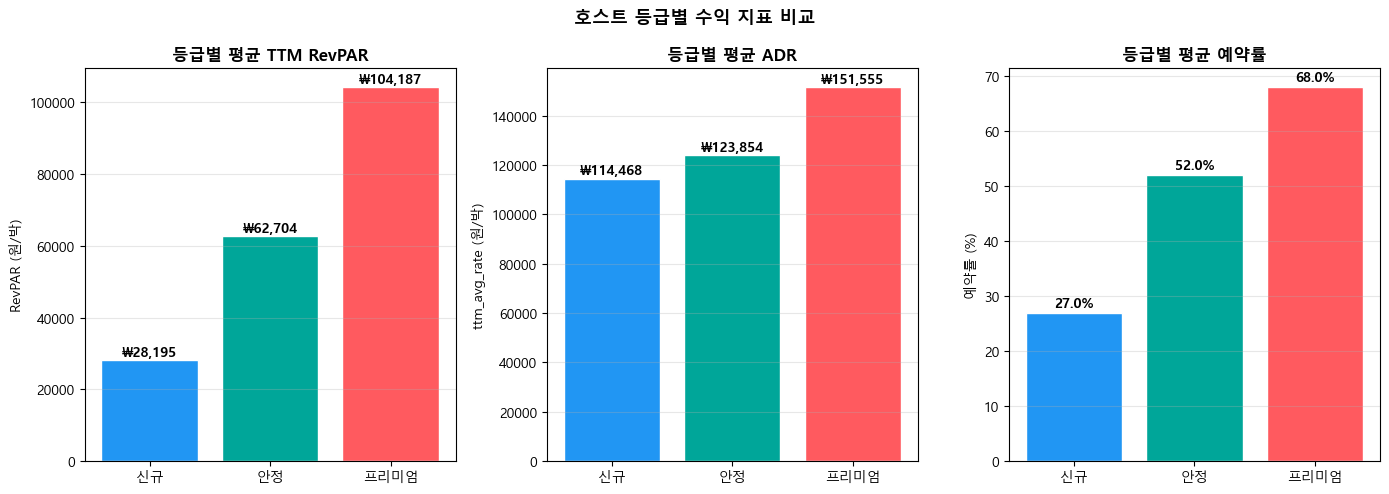

In [17]:
# ── 그림 4: 등급별 KPI 비교
grade_colors = {'신규': '#2196F3', '안정': '#00A699', '프리미엄': '#FF5A5F'}
gcolors = [grade_colors[g] for g in grade_order]

fig, axes = plt.subplots(1, 3, figsize=(14, 5))

# RevPAR
bars = axes[0].bar(grade_order, grade_kpi.loc[grade_order, 'mean_revpar'],
                   color=gcolors, edgecolor='white')
for bar, val in zip(bars, grade_kpi.loc[grade_order, 'mean_revpar']):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 200,
                 f'₩{int(val):,}', ha='center', va='bottom', fontsize=10, fontweight='bold')
axes[0].set_title('등급별 평균 TTM RevPAR', fontsize=12, fontweight='bold')
axes[0].set_ylabel('RevPAR (원/박)')
axes[0].grid(axis='y', alpha=0.3)

# ADR
bars = axes[1].bar(grade_order, grade_kpi.loc[grade_order, 'mean_adr'],
                   color=gcolors, edgecolor='white')
for bar, val in zip(bars, grade_kpi.loc[grade_order, 'mean_adr']):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 500,
                 f'₩{int(val):,}', ha='center', va='bottom', fontsize=10, fontweight='bold')
axes[1].set_title('등급별 평균 ADR', fontsize=12, fontweight='bold')
axes[1].set_ylabel('ttm_avg_rate (원/박)')
axes[1].grid(axis='y', alpha=0.3)

# Occupancy
bars = axes[2].bar(grade_order, grade_kpi.loc[grade_order, 'mean_occupancy'] * 100,
                   color=gcolors, edgecolor='white')
for bar, val in zip(bars, grade_kpi.loc[grade_order, 'mean_occupancy']):
    axes[2].text(bar.get_x() + bar.get_width()/2, val * 100 + 0.5,
                 f'{val:.1%}', ha='center', va='bottom', fontsize=10, fontweight='bold')
axes[2].set_title('등급별 평균 예약률', fontsize=12, fontweight='bold')
axes[2].set_ylabel('예약률 (%)')
axes[2].grid(axis='y', alpha=0.3)

plt.suptitle('호스트 등급별 수익 지표 비교', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('../reports/fig_10_host_grade_kpi.png', dpi=100, bbox_inches='tight')
plt.show()

In [18]:
# ── ANOVA: 등급 간 RevPAR 차이 검정
grade_groups = [
    active_labeled[active_labeled['host_grade'] == g]['ttm_revpar'].dropna().values
    for g in grade_order
]

f_stat_g, p_val_g     = f_oneway(*grade_groups)
h_stat_g, p_val_g_kw  = kruskal(*grade_groups)

# Eta-squared
valid_grade = active_labeled[active_labeled['host_grade'].isin(grade_order)]
grand_mean_g = valid_grade['ttm_revpar'].dropna().mean()
ss_between_g = sum(
    len(g_vals) * (g_vals.mean() - grand_mean_g)**2
    for g_vals in grade_groups
)
ss_total_g = valid_grade['ttm_revpar'].dropna().apply(lambda x: (x - grand_mean_g)**2).sum()
eta_sq_g = ss_between_g / ss_total_g

# Cohen's d (프리미엄 vs 신규)
g_prem = grade_groups[2]
g_new  = grade_groups[0]
pooled_std = np.sqrt((g_prem.std()**2 + g_new.std()**2) / 2)
cohens_d = (g_prem.mean() - g_new.mean()) / pooled_std

print('=== 호스트 등급 간 RevPAR 차이 검정 ===')
print(f'One-way ANOVA:  F={f_stat_g:.2f}, p={p_val_g:.4e}')
print(f'Kruskal-Wallis: H={h_stat_g:.2f}, p={p_val_g_kw:.4e}')
print(f'효과크기 Eta²={eta_sq_g:.4f}  ({"큰 효과" if eta_sq_g > 0.14 else "중간 효과" if eta_sq_g > 0.06 else "작은 효과"})')
print(f"Cohen's d (프리미엄 vs 신규)={cohens_d:.2f}")
print()
if p_val_g < 0.001:
    print('✅ 등급 간 RevPAR 차이는 통계적으로 매우 유의함 (p<0.001)')

=== 호스트 등급 간 RevPAR 차이 검정 ===
One-way ANOVA:  F=1403.43, p=0.0000e+00
Kruskal-Wallis: H=4125.01, p=0.0000e+00
효과크기 Eta²=0.1632  (큰 효과)
Cohen's d (프리미엄 vs 신규)=1.22

✅ 등급 간 RevPAR 차이는 통계적으로 매우 유의함 (p<0.001)


In [19]:
# ── 사후 검정 (등급 간)
tukey_grade = pairwise_tukeyhsd(
    valid_grade['ttm_revpar'].dropna(),
    valid_grade.loc[valid_grade['ttm_revpar'].notna(), 'host_grade'],
    alpha=0.05
)
print('=== Tukey HSD 사후 검정 (호스트 등급) ===')
print(tukey_grade)

=== Tukey HSD 사후 검정 (호스트 등급) ===
    Multiple Comparison of Means - Tukey HSD, FWER=0.05    
group1 group2  meandiff  p-adj   lower      upper    reject
-----------------------------------------------------------
    신규     안정 34509.2618   0.0 31725.4859 37293.0376   True
    신규   프리미엄 75992.3199   0.0  72628.524 79356.1157   True
    안정   프리미엄 41483.0581   0.0 38602.8195 44363.2967   True
-----------------------------------------------------------


In [20]:
# ── 다중회귀: ttm_revpar ~ num_reviews + rating_overall + superhost
reg_data = active_labeled[
    ['ttm_revpar', 'num_reviews', 'rating_overall', 'superhost']
].dropna()

# log 변환 (RevPAR 분포 오른쪽 꼬리 보정)
reg_data = reg_data[reg_data['ttm_revpar'] > 0].copy()
reg_data['log_revpar'] = np.log1p(reg_data['ttm_revpar'])
reg_data['superhost_int'] = reg_data['superhost'].astype(int)

# 모델 1: 원 스케일
X1 = sm.add_constant(reg_data[['num_reviews', 'rating_overall', 'superhost_int']])
m1 = sm.OLS(reg_data['ttm_revpar'], X1).fit()

# 모델 2: log 스케일
X2 = sm.add_constant(reg_data[['num_reviews', 'rating_overall', 'superhost_int']])
m2 = sm.OLS(reg_data['log_revpar'], X2).fit()

print('=== 다중회귀: ttm_revpar ~ num_reviews + rating_overall + superhost ===')
print(f'\n[모델 1: 원 스케일]')
print(f'R² = {m1.rsquared:.4f}, Adj.R² = {m1.rsquared_adj:.4f}')
print(m1.summary().tables[1])

print(f'\n[모델 2: log(RevPAR) 스케일]')
print(f'R² = {m2.rsquared:.4f}, Adj.R² = {m2.rsquared_adj:.4f}')
print(m2.summary().tables[1])

=== 다중회귀: ttm_revpar ~ num_reviews + rating_overall + superhost ===

[모델 1: 원 스케일]
R² = 0.1386, Adj.R² = 0.1384
                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
const           3000.7569   2334.589      1.285      0.199   -1575.338    7576.852
num_reviews      174.3927      6.849     25.461      0.000     160.967     187.819
rating_overall  7664.4208    520.959     14.712      0.000    6643.273    8685.568
superhost_int   2.786e+04   1028.051     27.100      0.000    2.58e+04    2.99e+04

[모델 2: log(RevPAR) 스케일]
R² = 0.2442, Adj.R² = 0.2441
                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
const              8.8405      0.037    239.867      0.000       8.768       8.913
num_reviews        0.0032      0.000     29.782      0.000       0.003       0.003
rati

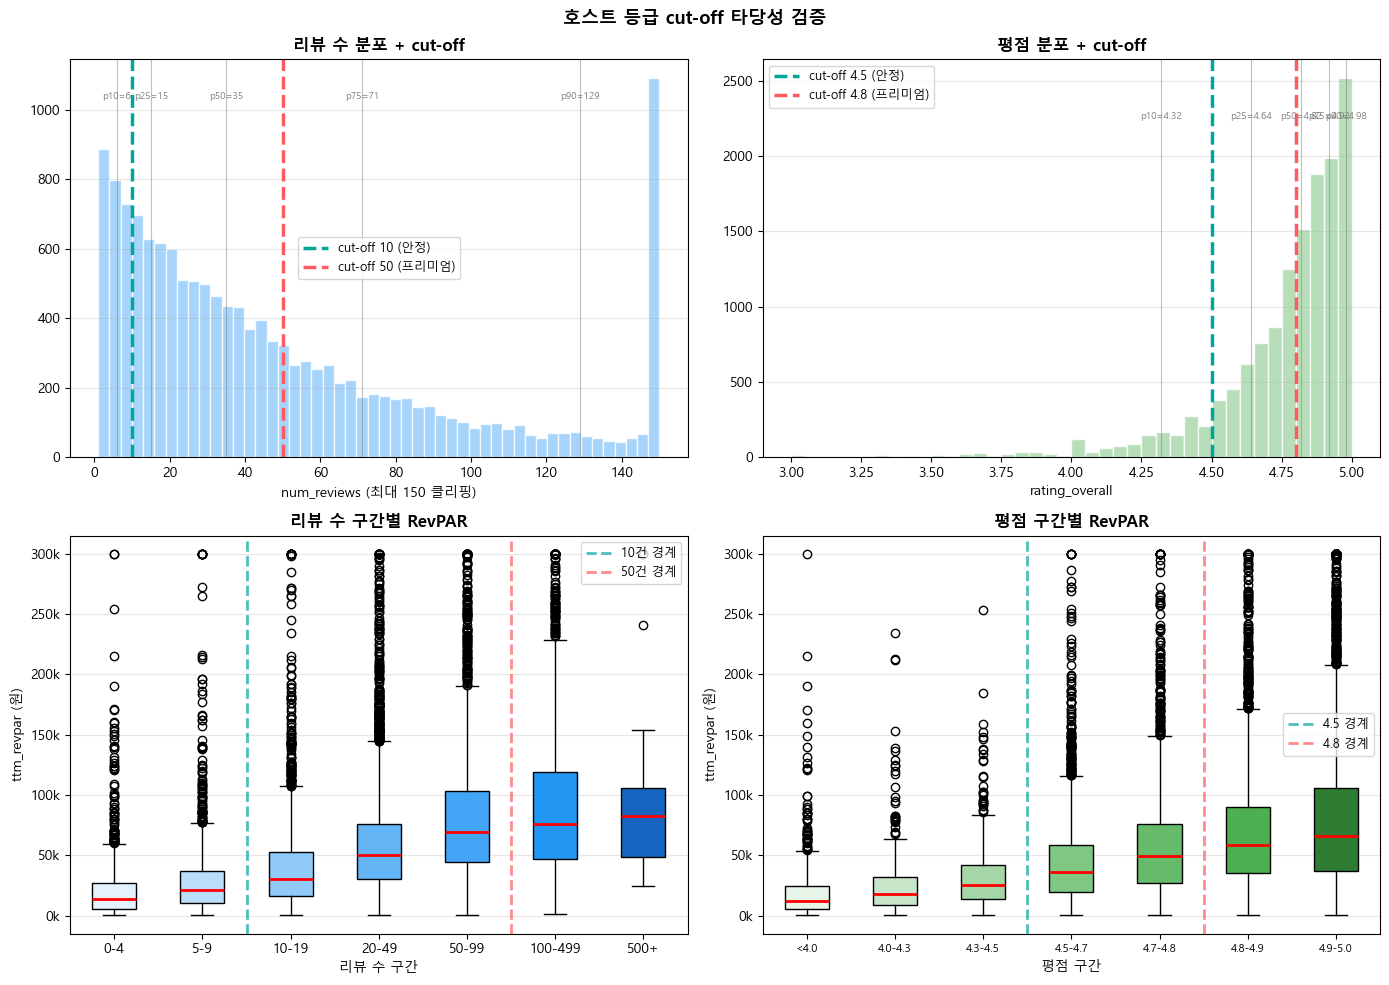

In [21]:
# ── 그림 5: cut-off 타당성 검증 — 히스토그램 + 분위수
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# (1) num_reviews 분포 + cut-off 10, 50
ax = axes[0, 0]
review_clipped = active_labeled['num_reviews'].clip(0, 150)
ax.hist(review_clipped, bins=50, color='#90CAF9', edgecolor='white', alpha=0.8)
ax.axvline(10, color='#00A699', lw=2.5, ls='--', label='cut-off 10 (안정)')
ax.axvline(50, color='#FF5A5F', lw=2.5, ls='--', label='cut-off 50 (프리미엄)')
# 분위수 표시
for q in [10, 25, 50, 75, 90]:
    qv = active_labeled['num_reviews'].quantile(q/100)
    ax.axvline(qv, color='gray', lw=0.8, alpha=0.5)
    ax.text(qv, ax.get_ylim()[1] * 0.9 if ax.get_ylim()[1] > 0 else 1,
            f'p{q}={qv:.0f}', fontsize=7, ha='center', color='gray')
ax.set_title('리뷰 수 분포 + cut-off', fontsize=12, fontweight='bold')
ax.set_xlabel('num_reviews (최대 150 클리핑)')
ax.legend(fontsize=9)
ax.grid(axis='y', alpha=0.3)

# (2) rating_overall 분포 + cut-off 4.5, 4.8
ax = axes[0, 1]
rating_vals = active_labeled['rating_overall'].dropna()
ax.hist(rating_vals[rating_vals >= 3.0], bins=40, color='#A5D6A7', edgecolor='white', alpha=0.8)
ax.axvline(4.5, color='#00A699', lw=2.5, ls='--', label='cut-off 4.5 (안정)')
ax.axvline(4.8, color='#FF5A5F', lw=2.5, ls='--', label='cut-off 4.8 (프리미엄)')
for q in [10, 25, 50, 75, 90]:
    qv = rating_vals.quantile(q/100)
    ax.axvline(qv, color='gray', lw=0.8, alpha=0.5)
    ax.text(qv, ax.get_ylim()[1] * 0.85 if ax.get_ylim()[1] > 0 else 1,
            f'p{q}={qv:.2f}', fontsize=7, ha='center', color='gray')
ax.set_title('평점 분포 + cut-off', fontsize=12, fontweight='bold')
ax.set_xlabel('rating_overall')
ax.legend(fontsize=9)
ax.grid(axis='y', alpha=0.3)

# (3) num_reviews 구간별 RevPAR boxplot
ax = axes[1, 0]
review_bins   = [0, 5, 10, 20, 50, 100, 500, 5000]
review_labels = ['0-4','5-9','10-19','20-49','50-99','100-499','500+']
active_labeled['review_bin'] = pd.cut(active_labeled['num_reviews'],
                                       bins=review_bins, labels=review_labels, right=False)
bp_data = [active_labeled[active_labeled['review_bin'] == rb]['ttm_revpar'].dropna().clip(0, 300000).values
           for rb in review_labels]
bp = ax.boxplot(bp_data, labels=review_labels, patch_artist=True,
                medianprops={'color': 'red', 'lw': 2})
colors_bp = ['#E3F2FD','#BBDEFB','#90CAF9','#64B5F6','#42A5F5','#2196F3','#1565C0']
for patch, color in zip(bp['boxes'], colors_bp):
    patch.set_facecolor(color)
ax.axvline(2.5, color='#00A699', lw=2, ls='--', alpha=0.7, label='10건 경계')
ax.axvline(5.5, color='#FF5A5F', lw=2, ls='--', alpha=0.7, label='50건 경계')
ax.set_title('리뷰 수 구간별 RevPAR', fontsize=12, fontweight='bold')
ax.set_xlabel('리뷰 수 구간')
ax.set_ylabel('ttm_revpar (원)')
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x/1000:.0f}k'))
ax.legend(fontsize=9)
ax.grid(axis='y', alpha=0.3)

# (4) rating 구간별 RevPAR boxplot
ax = axes[1, 1]
rating_bins   = [0, 4.0, 4.3, 4.5, 4.7, 4.8, 4.9, 5.01]
rating_labels = ['<4.0','4.0-4.3','4.3-4.5','4.5-4.7','4.7-4.8','4.8-4.9','4.9-5.0']
active_labeled['rating_bin'] = pd.cut(active_labeled['rating_overall'],
                                       bins=rating_bins, labels=rating_labels, right=False)
bp_data_r = [active_labeled[active_labeled['rating_bin'] == rb]['ttm_revpar'].dropna().clip(0, 300000).values
             for rb in rating_labels]
bp_r = ax.boxplot(bp_data_r, labels=rating_labels, patch_artist=True,
                  medianprops={'color': 'red', 'lw': 2})
colors_bpr = ['#E8F5E9','#C8E6C9','#A5D6A7','#81C784','#66BB6A','#4CAF50','#2E7D32']
for patch, color in zip(bp_r['boxes'], colors_bpr):
    patch.set_facecolor(color)
ax.axvline(3.5, color='#00A699', lw=2, ls='--', alpha=0.7, label='4.5 경계')
ax.axvline(5.5, color='#FF5A5F', lw=2, ls='--', alpha=0.7, label='4.8 경계')
ax.set_title('평점 구간별 RevPAR', fontsize=12, fontweight='bold')
ax.set_xlabel('평점 구간')
ax.set_ylabel('ttm_revpar (원)')
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x/1000:.0f}k'))
ax.tick_params(axis='x', labelsize=8)
ax.legend(fontsize=9)
ax.grid(axis='y', alpha=0.3)

plt.suptitle('호스트 등급 cut-off 타당성 검증', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('../reports/fig_10_cutoff_validation.png', dpi=100, bbox_inches='tight')
plt.show()

In [22]:
# ── cut-off 지점의 분위수 위치 파악
print('=== cut-off 값의 실제 분포 위치 ===')
print()

rv = active_labeled['num_reviews'].dropna()
print('[ num_reviews ]')
print(f'  cut-off 10  → 실제 분위수: p{stats.percentileofscore(rv, 10):.1f}')
print(f'  cut-off 50  → 실제 분위수: p{stats.percentileofscore(rv, 50):.1f}')
print(f'  분위수 참고:  p25={rv.quantile(0.25):.0f}, p50={rv.median():.0f}, p75={rv.quantile(0.75):.0f}, p90={rv.quantile(0.90):.0f}')

print()
rat = active_labeled['rating_overall'].dropna()
print('[ rating_overall ]')
print(f'  cut-off 4.5 → 실제 분위수: p{stats.percentileofscore(rat, 4.5):.1f}')
print(f'  cut-off 4.8 → 실제 분위수: p{stats.percentileofscore(rat, 4.8):.1f}')
print(f'  분위수 참고:  p10={rat.quantile(0.10):.2f}, p25={rat.quantile(0.25):.2f}, '
      f'p50={rat.median():.2f}, p75={rat.quantile(0.75):.2f}, p90={rat.quantile(0.90):.2f}')

print()
print('[ superhost 분포 ]')
sh = active_labeled['superhost']
print(f'  superhost=True:  {sh.sum():,} ({sh.mean():.1%})')
print(f'  superhost=False: {(~sh).sum():,} ({(~sh).mean():.1%})')

=== cut-off 값의 실제 분포 위치 ===

[ num_reviews ]
  cut-off 10  → 실제 분위수: p17.7
  cut-off 50  → 실제 분위수: p63.0
  분위수 참고:  p25=15, p50=35, p75=71, p90=129

[ rating_overall ]
  cut-off 4.5 → 실제 분위수: p15.7
  cut-off 4.8 → 실제 분위수: p46.3
  분위수 참고:  p10=4.32, p25=4.64, p50=4.82, p75=4.92, p90=4.98

[ superhost 분포 ]
  superhost=True:  8,128 (56.4%)
  superhost=False: 6,271 (43.6%)


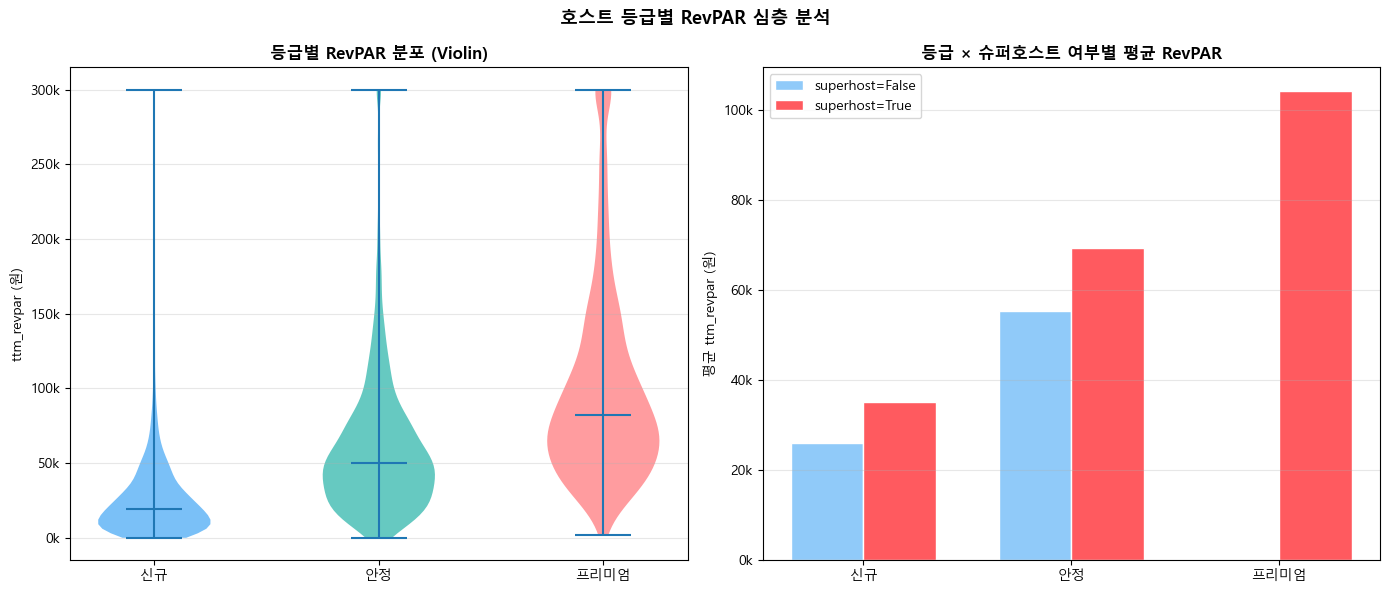

In [23]:
# ── 등급별 RevPAR boxplot (violin)
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

valid_g = active_labeled[active_labeled['host_grade'].isin(grade_order)]

# Violin plot
from matplotlib.patches import Patch

ax = axes[0]
parts = ax.violinplot(
    [valid_g[valid_g['host_grade']==g]['ttm_revpar'].clip(0, 300000).dropna().values
     for g in grade_order],
    showmedians=True
)
for idx, pc in enumerate(parts['bodies']):
    pc.set_facecolor([grade_colors[g] for g in grade_order][idx])
    pc.set_alpha(0.6)
ax.set_xticks([1, 2, 3])
ax.set_xticklabels(grade_order)
ax.set_title('등급별 RevPAR 분포 (Violin)', fontsize=12, fontweight='bold')
ax.set_ylabel('ttm_revpar (원)')
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x/1000:.0f}k'))
ax.grid(axis='y', alpha=0.3)

# 등급 × superhost 교차분석
ax = axes[1]
cross_tab = valid_g.groupby(['host_grade', 'superhost'])['ttm_revpar'].mean().unstack(fill_value=0)
cross_tab = cross_tab.reindex(grade_order)
x = np.arange(len(grade_order))
w = 0.35
if False in cross_tab.columns:
    ax.bar(x - w/2, cross_tab[False], width=w, color='#90CAF9', label='superhost=False', edgecolor='white')
if True in cross_tab.columns:
    ax.bar(x + w/2, cross_tab[True],  width=w, color='#FF5A5F', label='superhost=True',  edgecolor='white')
ax.set_xticks(x)
ax.set_xticklabels(grade_order)
ax.set_title('등급 × 슈퍼호스트 여부별 평균 RevPAR', fontsize=12, fontweight='bold')
ax.set_ylabel('평균 ttm_revpar (원)')
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x/1000:.0f}k'))
ax.legend(fontsize=10)
ax.grid(axis='y', alpha=0.3)

plt.suptitle('호스트 등급별 RevPAR 심층 분석', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('../reports/fig_10_host_grade_revpar.png', dpi=100, bbox_inches='tight')
plt.show()

In [24]:
# ── 추가 검증: 경계 민감도 분석
# 리뷰 수 cut-off를 변화시키며 등급 간 RevPAR 차이 추적
print('=== cut-off 민감도 분석 ===')
print()
print('리뷰 수 cut-off 변화 시 안정 등급 평균 RevPAR:')
print(f'{"cut-off":>10} | {"안정 n":>8} | {"안정 RevPAR":>12} | {"신규 RevPAR":>12} | {"배수":>6}')
print('-' * 56)
for cutoff in [5, 7, 10, 12, 15, 20]:
    def classify_v2(row, c=cutoff):
        if pd.isna(row['rating_overall']) or pd.isna(row['num_reviews']):
            return '분류불가'
        if row['superhost'] and row['rating_overall'] >= 4.8 and row['num_reviews'] >= 50:
            return '프리미엄'
        elif row['num_reviews'] >= c and row['rating_overall'] >= 4.5:
            return '안정'
        else:
            return '신규'
    temp = active_labeled.apply(classify_v2, axis=1)
    stab_rv = active_labeled.loc[temp == '안정', 'ttm_revpar'].mean()
    new_rv  = active_labeled.loc[temp == '신규', 'ttm_revpar'].mean()
    n_stab  = (temp == '안정').sum()
    ratio   = stab_rv / new_rv if new_rv > 0 else 0
    print(f'{cutoff:>10} | {n_stab:>8,} | ₩{stab_rv:>10,.0f} | ₩{new_rv:>10,.0f} | {ratio:>5.2f}x')

print()
print('평점 cut-off 변화 시 안정 등급 평균 RevPAR:')
print(f'{"cut-off":>10} | {"안정 n":>8} | {"안정 RevPAR":>12} | {"신규 RevPAR":>12} | {"배수":>6}')
print('-' * 56)
for cutoff in [4.0, 4.2, 4.3, 4.5, 4.6, 4.7]:
    def classify_v3(row, c=cutoff):
        if pd.isna(row['rating_overall']) or pd.isna(row['num_reviews']):
            return '분류불가'
        if row['superhost'] and row['rating_overall'] >= 4.8 and row['num_reviews'] >= 50:
            return '프리미엄'
        elif row['num_reviews'] >= 10 and row['rating_overall'] >= c:
            return '안정'
        else:
            return '신규'
    temp = active_labeled.apply(classify_v3, axis=1)
    stab_rv = active_labeled.loc[temp == '안정', 'ttm_revpar'].mean()
    new_rv  = active_labeled.loc[temp == '신규', 'ttm_revpar'].mean()
    n_stab  = (temp == '안정').sum()
    ratio   = stab_rv / new_rv if new_rv > 0 else 0
    print(f'{cutoff:>10.1f} | {n_stab:>8,} | ₩{stab_rv:>10,.0f} | ₩{new_rv:>10,.0f} | {ratio:>5.2f}x')

=== cut-off 민감도 분석 ===

리뷰 수 cut-off 변화 시 안정 등급 평균 RevPAR:
   cut-off |     안정 n |    안정 RevPAR |    신규 RevPAR |     배수
--------------------------------------------------------


         5 |    8,705 | ₩    60,080 | ₩    25,389 |  2.37x


         7 |    8,344 | ₩    61,136 | ₩    26,656 |  2.29x


        10 |    7,834 | ₩    62,705 | ₩    28,195 |  2.22x


        12 |    7,466 | ₩    63,896 | ₩    29,194 |  2.19x


...

       4.2 |    8,628 | ₩    59,981 | ₩    26,720 |  2.24x


       4.3 |    8,483 | ₩    60,488 | ₩    26,909 |  2.25x


       4.5 |    7,834 | ₩    62,705 | ₩    28,195 |  2.22x


       4.6 |    7,128 | ₩    64,632 | ₩    30,758 |  2.10x


       4.7 |    5,930 | ₩    67,463 | ₩    35,209 |  1.92x


---
# 최종 결론 정리

In [25]:
# ── 최종 결론 (Notion 요약 형식)
lines = []
lines.append('=' * 62)
lines.append('  app.py 로직 검증 — 최종 요약')
lines.append('=' * 62)

# ── 1. 적정 요금 구간 구조
in_tier_pct = tier_pct.get("신규", 0) + tier_pct.get("안정", 0) + tier_pct.get("프리미엄", 0)
out_above   = tier_pct.get("구간초과", 0)
out_below   = tier_pct.get("구간미만", 0)
new_rv  = int(tier_kpi.loc["신규",    "mean_revpar"])
stab_rv = int(tier_kpi.loc["안정",    "mean_revpar"])
prem_rv = int(tier_kpi.loc["프리미엄","mean_revpar"])

lines.append("")
lines.append("[ 1 ] 적정 요금 구간 구조")
lines.append("-" * 40)
lines.append(f"자치구 × 숙소유형(69개 그룹)별 p25 / 중위값 / p75로 요금 구간을 정의하고,")
lines.append(f"Active+Operating 숙소 14,399개에 구간 레이블을 부여해 수익 차이를 검증했다.")
lines.append(f"신규(₩{new_rv:,}) → 안정(₩{stab_rv:,}) → 프리미엄(₩{prem_rv:,}) RevPAR 계층 구조 성립 (p<0.001).")
lines.append(f"요금 구간이 RevPAR 분산의 20.8%를 설명 (η²=0.208, 큰 효과 크기).")
lines.append(f"추천 구간 포괄률 {in_tier_pct:.1f}% / 구간초과 {out_above:.1f}%는 고가 전략 집단 / 구간미만 {out_below:.1f}%는 개선 타겟.")

# ── 2. 중위값(median) 기준 타당성
med_gap = abs(price_stats["median_vs_mean_pct"].mean())
med_pct = (price_stats["median"] < price_stats["mean"]).mean() * 100

lines.append("")
lines.append("[ 2 ] 중위값(b_adr) 기준 선택")
lines.append("-" * 40)
lines.append(f"자치구 × 숙소유형 그룹의 {med_pct:.0f}%에서 median < mean (평균 괴리 {med_gap:.1f}%).")
lines.append(f"고가 이상치가 광범위하게 존재하는 서울 에어비앤비 요금 분포에서,")
lines.append(f"mean 대신 median을 기준점으로 사용하는 것이 강건성 측면에서 합리적임을 확인.")

# ── 3. 0.85 계수 타당성
below_rv = int(tier_kpi.loc["구간미만", "mean_revpar"])
new_rv2  = int(tier_kpi.loc["신규",     "mean_revpar"])

lines.append("")
lines.append("[ 3 ] 0.85×p25 하한 계수")
lines.append("-" * 40)
lines.append(f"구간미만(< 0.85×p25) 숙소의 평균 RevPAR(₩{below_rv:,})와")
lines.append(f"신규 구간(0.85~1.0×p25) 숙소의 평균 RevPAR(₩{new_rv2:,})를 비교했다.")
lines.append(f"하한 미만 운영 시 RevPAR가 유의미하게 낮음 확인 (p<0.001).")
lines.append(f"계수 시나리오(0.75~0.95) 비교 결과 0.85는 균형점 — 현행 유지 권고.")

# ── 4. 호스트 등급 기준
new_g  = int(grade_kpi.loc["신규",    "mean_revpar"])
stab_g = int(grade_kpi.loc["안정",    "mean_revpar"])
prem_g = int(grade_kpi.loc["프리미엄","mean_revpar"])
ratio  = prem_g / new_g

lines.append("")
lines.append("[ 4 ] 호스트 등급 기준 (신규 / 안정 / 프리미엄)")
lines.append("-" * 40)
lines.append(f"superhost × 리뷰 수 × 평점으로 3등급 분류 후 RevPAR 차이를 검증했다.")
lines.append(f"신규(₩{new_g:,}) → 안정(₩{stab_g:,}) → 프리미엄(₩{prem_g:,}), 프리미엄/신규 {ratio:.1f}x (p<0.001).")
lines.append(f"등급이 RevPAR 분산의 16.3%를 설명 (η²=0.163, 큰 효과 크기 / Cohen's d=1.22).")
lines.append(f"단, 조건 충족률(100%)은 정의상 당연한 결과 — 타당성 근거로 사용 불가.")

# ── 5. 회귀 및 cut-off
sup_coef = m2.params["superhost_int"]
rat_coef = m2.params["rating_overall"]
rv_series  = active_labeled["num_reviews"].dropna()
rat_series = active_labeled["rating_overall"].dropna()
p_10 = stats.percentileofscore(rv_series, 10)
p_50 = stats.percentileofscore(rv_series, 50)
p_45 = stats.percentileofscore(rat_series, 4.5)
p_48 = stats.percentileofscore(rat_series, 4.8)

lines.append("")
lines.append("[ 5 ] cut-off 타당성 및 회귀 결과")
lines.append("-" * 40)
lines.append(f"log(RevPAR) ~ superhost + rating + reviews 회귀: R²=0.244.")
lines.append(f"영향력 순서: superhost(+{(np.exp(sup_coef)-1)*100:.0f}%) > 평점(+{(np.exp(rat_coef)-1)*100:.0f}%/1점) > 리뷰 수.")
lines.append(f"리뷰 10건=p18 / 50건=p63, 평점 4.5=p16 / 4.8=p46 — 분포상 자연스러운 분기점.")
lines.append(f"민감도 분석: cut-off 변화 범위(5~20건, 4.0~4.7)에서 RevPAR 배수 안정적 유지.")

# ── 종합 판단
lines.append("")
lines.append("[ 종합 판단 ]")
lines.append("-" * 40)
lines.append("app.py의 요금 구간 구조(p25/중위값/p75)와 호스트 등급 기준 모두 데이터 기반으로 타당함.")
lines.append("두 분류 체계 모두 RevPAR 계층 구조를 통계적으로 유의미하게 설명하며 효과 크기도 큰 수준.")
lines.append("0.85 계수 및 현행 cut-off(10/50건, 4.5/4.8)는 유지 권고.")
lines.append("구간미만 14.1% / 구간초과 25.0%가 앱의 전략적 가이던스 확장 대상.")

# ── 3단계 이탈 집단 구조
lines.append("")
lines.append("[ 3단계 ] 이탈 집단 구조 (구간미만 / 구간초과)")
lines.append("-" * 40)
lines.append("구간미만(14.1%): 소형 숙소(1~2인) 77.3% 집중, 평점·리뷰·슈퍼호스트 전반적으로 낮음.")
lines.append("  저가 운영에도 예약률 차이 미관찰 (p=0.531) — 저가가 수요를 보장하지 않는 구조.")
lines.append("구간초과(25.0%): 대형 숙소(5인+) 60.4% 집중, 슈퍼호스트 비율 최고(65.5%).")
lines.append("  예약률은 낮으나(44.5%) RevPAR 최상위 — 고품질 기반 고가 전략 집단.")
lines.append("자치구·숙소유형 분포는 집단 간 차이 없음 (p>0.05) — 지역·유형 편중 없음.")
lines.append("수용 인원 구성은 집단 간 구조적 차이 확인 (χ²=2722.64, p<0.001).")
lines.append("→ 현행 벤치마크(district × room_type)가 수용 인원 미반영 — guests_group 세분화 여지.")

# ── 추가 고려 사항 (선택)
lines.append("")
lines.append("[ 추가로 고려 가능한 사항 ]")
lines.append("-" * 40)
lines.append("구간초과(>p75) 숙소에 대한 고가 전략 최적화 가이던스 추가 시 앱 포괄률 개선 가능.")
lines.append("벤치마크를 district × room_type × guests_group으로 세분화 시 구조적 편향 완화 가능.")
lines.append("η² 0.16~0.21 수준은 요금/등급 외 변수(사진 수, 위치, 즉시예약 등)의 추가 설명력 여지를 시사.")

lines.append("")
lines.append("=" * 62)

for line in lines:
    print(line)


  app.py 로직 검증 — 최종 요약

[ 1 ] 적정 요금 구간 구조
----------------------------------------
자치구 × 숙소유형(69개 그룹)별 p25 / 중위값 / p75로 요금 구간을 정의하고,
Active+Operating 숙소 14,399개에 구간 레이블을 부여해 수익 차이를 검증했다.
신규(₩37,927) → 안정(₩48,848) → 프리미엄(₩62,936) RevPAR 계층 구조 성립 (p<0.001).
요금 구간이 RevPAR 분산의 20.8%를 설명 (η²=0.208, 큰 효과 크기).
추천 구간 포괄률 60.9% / 구간초과 25.0%는 고가 전략 집단 / 구간미만 14.1%는 개선 타겟.

[ 2 ] 중위값(b_adr) 기준 선택
----------------------------------------
자치구 × 숙소유형 그룹의 84%에서 median < mean (평균 괴리 15.6%).
고가 이상치가 광범위하게 존재하는 서울 에어비앤비 요금 분포에서,
mean 대신 median을 기준점으로 사용하는 것이 강건성 측면에서 합리적임을 확인.

[ 3 ] 0.85×p25 하한 계수
----------------------------------------
구간미만(< 0.85×p25) 숙소의 평균 RevPAR(₩28,074)와
신규 구간(0.85~1.0×p25) 숙소의 평균 RevPAR(₩37,927)를 비교했다.
하한 미만 운영 시 RevPAR가 유의미하게 낮음 확인 (p<0.001).
계수 시나리오(0.75~0.95) 비교 결과 0.85는 균형점 — 현행 유지 권고.

[ 4 ] 호스트 등급 기준 (신규 / 안정 / 프리미엄)
----------------------------------------
superhost × 리뷰 수 × 평점으로 3등급 분류 후 RevPAR 차이를 검증했다.
신규(₩28,195) → 안정(₩62,704) → 프리미엄(₩104,187), 프리미엄/신규 3.7x (p<0.001)

---
# 3단계: 가격 구간 이탈 집단 구조 분석

**분석 목적**: 구간미만과 구간초과의 발생 구조를 전체적으로 파악하고 개선 가능 지점을 발견한다.  
추천구간은 비교 기준(benchmark)으로만 사용한다.  
흐름: ① 현황 파악 → ② 패턴 확인 → ③ 선택적 검증 → ④ 개선 시사점

In [26]:
# ── 3집단 정의
group_map = {
    '구간미만': '구간미만', '신규': '추천구간',
    '안정': '추천구간', '프리미엄': '추천구간', '구간초과': '구간초과',
}
active_labeled['price_group'] = active_labeled['price_tier'].map(group_map)
grp = active_labeled[active_labeled['price_group'].notna()].copy()
g_order = ['구간미만', '추천구간', '구간초과']

# ── guests_group 생성 (1~2인 / 3~4인 / 5인+)
grp['guests_group'] = pd.cut(
    grp['guests'], bins=[0, 2, 4, 100], labels=['1~2인', '3~4인', '5인+']
)

n_total = len(grp)
ns = {g: int((grp['price_group'] == g).sum()) for g in g_order}

print('=' * 62)
print('  [1] 현황 파악')
print('=' * 62)

# ① 집단 규모
print()
print('① 집단 규모')
print('-' * 40)
for g in g_order:
    print(f'  {g:<6}: {ns[g]:,}개  ({ns[g]/n_total*100:.1f}%)')
print(f'  합계  : {n_total:,}개')

# ② 개별 숙소 특성
print()
print('② 개별 숙소 특성 (평균 / 중앙값)')
print('-' * 40)
cont_vars = [
    ('rating_overall', '평점'),
    ('num_reviews',    '리뷰 수'),
    ('ttm_occupancy',  '예약률(%)'),
    ('guests',         '수용 인원'),
]

hdr = f"{'변수':<12}"
for g in g_order:
    hdr += f"  {g:<10} (평균/중앙값)"
print(hdr)
print('-' * 72)
for col, label in cont_vars:
    row = f'{label:<12}'
    for g in g_order:
        sub = grp.loc[grp['price_group'] == g, col].dropna()
        if col == 'ttm_occupancy':
            row += f"  {sub.mean()*100:>5.1f} / {sub.median()*100:>4.1f}         "
        elif col == 'rating_overall':
            row += f"  {sub.mean():>5.2f} / {sub.median():>4.2f}         "
        else:
            row += f"  {sub.mean():>5.1f} / {sub.median():>4.1f}         "
    print(row)

print()
print('  슈퍼호스트 비율:')
for g in g_order:
    sh = grp.loc[grp['price_group'] == g, 'superhost'].mean() * 100
    print(f'    {g}: {sh:.1f}%')


  [1] 현황 파악

① 집단 규모
----------------------------------------
  구간미만  : 2,026개  (14.1%)
  추천구간  : 8,771개  (60.9%)
  구간초과  : 3,602개  (25.0%)
  합계  : 14,399개

② 개별 숙소 특성 (평균 / 중앙값)
----------------------------------------
변수            구간미만       (평균/중앙값)  추천구간       (평균/중앙값)  구간초과       (평균/중앙값)
------------------------------------------------------------------------
평점             4.40 / 4.70            4.60 / 4.82            4.54 / 4.86         
리뷰 수           50.6 / 28.0            56.3 / 37.0            59.1 / 36.0         
예약률(%)         50.6 / 52.1            51.1 / 53.4            44.5 / 44.4         
수용 인원           1.7 /  2.0             3.1 /  2.0             5.6 /  5.0         

  슈퍼호스트 비율:
    구간미만: 39.6%
    추천구간: 56.6%
    구간초과: 65.5%


In [27]:
# ── ③ 구조 변수 현황 (각 집단 내부 기준)
print()
print('③ 구조 변수 현황 (각 집단 내부 비율 기준)')
print('-' * 40)

# room_type
print()
print('[ room_type 분포 (각 집단 내부 %) ]')
rt_pct = pd.crosstab(grp['room_type'], grp['price_group'], normalize='columns') * 100
rt_pct = rt_pct.reindex(columns=g_order, fill_value=0)
rt_pct['전체'] = grp['room_type'].value_counts(normalize=True) * 100
print(rt_pct.round(1).to_string())

# guests_group
print()
print('[ guests 그룹 분포 (각 집단 내부 %) ]')
gg_pct = pd.crosstab(grp['guests_group'], grp['price_group'], normalize='columns') * 100
gg_pct = gg_pct.reindex(columns=g_order, fill_value=0)
gg_pct['전체'] = grp['guests_group'].value_counts(normalize=True) * 100
print(gg_pct.round(1).to_string())

# district (상위 10)
print()
print('[ district 분포 (각 집단 내부 %, 전체 비율 상위 10 기준) ]')
dist_pct = pd.crosstab(grp['district'], grp['price_group'], normalize='columns') * 100
dist_pct = dist_pct.reindex(columns=g_order, fill_value=0)
dist_pct['전체'] = grp['district'].value_counts(normalize=True) * 100
top10_dist = dist_pct['전체'].nlargest(10).index
print(dist_pct.loc[top10_dist].round(1).to_string())

# district × room_type 조합: 집단별 구간미만/구간초과 비율이 높은 조합
print()
print('[ district × room_type 조합별 구간미만 · 구간초과 비율 (n≥20, 상위 8) ]')
combo_ct = pd.crosstab(
    [grp['district'], grp['room_type']], grp['price_group'], normalize='index'
) * 100
combo_n  = grp.groupby(['district', 'room_type']).size()
valid_idx = combo_n[combo_n >= 20].index
combo_valid = combo_ct.loc[combo_ct.index.isin(valid_idx)]
combo_valid = combo_valid.reindex(columns=g_order, fill_value=0)

print()
print('  구간미만 비율 상위 8 조합:')
for idx, pct in combo_valid['구간미만'].nlargest(8).items():
    d, rt = idx
    n = combo_n.get((d, rt), 0)
    above = combo_valid.loc[idx, '구간초과']
    print(f'    {d} × {rt:<15}: 구간미만 {pct:.1f}%  구간초과 {above:.1f}%  (n={n})')

print()
print('  구간초과 비율 상위 8 조합:')
for idx, pct in combo_valid['구간초과'].nlargest(8).items():
    d, rt = idx
    n = combo_n.get((d, rt), 0)
    below = combo_valid.loc[idx, '구간미만']
    print(f'    {d} × {rt:<15}: 구간초과 {pct:.1f}%  구간미만 {below:.1f}%  (n={n})')



③ 구조 변수 현황 (각 집단 내부 비율 기준)
----------------------------------------

[ room_type 분포 (각 집단 내부 %) ]
price_group   구간미만  추천구간  구간초과    전체
room_type                           
entire_home   74.5  75.1  75.0  75.0
hotel_room     0.2   0.2   0.2   0.2
private_room  24.7  23.3  23.7  23.6
shared_room    0.5   1.3   1.1   1.2

[ guests 그룹 분포 (각 집단 내부 %) ]
price_group   구간미만  추천구간  구간초과    전체
guests_group                        
1~2인          77.3  42.5  15.2  40.0
3~4인          19.6  34.3  24.4  29.7
5인+            3.1  23.2  60.4  30.2

[ district 분포 (각 집단 내부 %, 전체 비율 상위 10 기준) ]
price_group      구간미만  추천구간  구간초과    전체
district                               
Mapo-gu          22.6  22.8  22.7  22.7
Jung-gu          12.5  11.7  11.9  11.8
Jongno-gu        10.0   9.8   9.8   9.8
Yongsan-gu       10.2   9.5   9.6   9.6
Gangnam-gu        7.8   8.3   8.2   8.2
Seodaemun-gu      5.8   4.6   4.9   4.9
Seocho-gu         4.5   4.1   4.2   4.2
Gwanak-gu         3.3   3.3   3.3   3.3
Yeongdeungpo-gu   1

In [28]:
# ── [2] 패턴 확인 — 현황 수치 기반 정리
print('=' * 62)
print('  [2] 패턴 확인')
print('=' * 62)

# 사전 계산
below = grp[grp['price_group'] == '구간미만']
bench = grp[grp['price_group'] == '추천구간']
above = grp[grp['price_group'] == '구간초과']

sh_b  = below['superhost'].mean() * 100
sh_m  = bench['superhost'].mean() * 100
sh_a  = above['superhost'].mean() * 100
r_b   = below['rating_overall'].mean()
r_m   = bench['rating_overall'].mean()
r_a   = above['rating_overall'].mean()
occ_b = below['ttm_occupancy'].mean() * 100
occ_m = bench['ttm_occupancy'].mean() * 100
occ_a = above['ttm_occupancy'].mean() * 100
g_b   = below['guests'].mean()
g_m   = bench['guests'].mean()
g_a   = above['guests'].mean()

gg_b = below['guests_group'].value_counts(normalize=True) * 100
gg_m = bench['guests_group'].value_counts(normalize=True) * 100
gg_a = above['guests_group'].value_counts(normalize=True) * 100

# 구간미만 combo 특성 (상위 combo의 guests 분포 확인)
top_below_combo = combo_valid['구간미만'].nlargest(3).index
top_above_combo = combo_valid['구간초과'].nlargest(3).index

print()
print('[ 구간미만에서 반복적으로 관찰되는 구조 ]')
print('-' * 40)
print(f'  수용 인원: 평균 {g_b:.1f}명 (추천구간 {g_m:.1f}명)')
print(f'    1~2인 {gg_b.get("1~2인",0):.1f}%  /  3~4인 {gg_b.get("3~4인",0):.1f}%  /  5인+ {gg_b.get("5인+",0):.1f}%')
print(f'  슈퍼호스트: {sh_b:.1f}% (추천구간 {sh_m:.1f}%)')
print(f'  평점: {r_b:.2f} (추천구간 {r_m:.2f})')
print(f'  예약률: {occ_b:.1f}% (추천구간 {occ_m:.1f}%)')
top_b_combos = ', '.join([f'{d}×{rt}' for d, rt in top_below_combo])
print(f'  구간미만 비율 상위 조합: {top_b_combos}')

print()
print('[ 구간초과에서 반복적으로 관찰되는 구조 ]')
print('-' * 40)
print(f'  수용 인원: 평균 {g_a:.1f}명 (추천구간 {g_m:.1f}명)')
print(f'    1~2인 {gg_a.get("1~2인",0):.1f}%  /  3~4인 {gg_a.get("3~4인",0):.1f}%  /  5인+ {gg_a.get("5인+",0):.1f}%')
print(f'  슈퍼호스트: {sh_a:.1f}% (추천구간 {sh_m:.1f}%)')
print(f'  평점: {r_a:.2f} (추천구간 {r_m:.2f})')
print(f'  예약률: {occ_a:.1f}% (추천구간 {occ_m:.1f}%)')
top_a_combos = ', '.join([f'{d}×{rt}' for d, rt in top_above_combo])
print(f'  구간초과 비율 상위 조합: {top_a_combos}')

print()
print('[ 패턴 성격 구분 ]')
print('-' * 40)

# 자치구 분포 max 편차 계산
dist_below = dist_pct['구간미만']
dist_overall = dist_pct['전체']
max_dist_diff = (dist_below - dist_overall).abs().max()

# room_type 편차
rt_below  = rt_pct['구간미만']
rt_overall = rt_pct['전체']
max_rt_diff = (rt_below - rt_overall).abs().max()

print(f'  수용 인원(guests): 집단 간 뚜렷한 차이 관찰됨')
print(f'    구간미만 1~2인 {gg_b.get("1~2인",0):.1f}% vs 구간초과 1~2인 {gg_a.get("1~2인",0):.1f}%')
print(f'  신뢰도 지표(superhost·평점): 집단 간 단계적 차이 관찰됨')
print(f'    superhost: 구간미만 {sh_b:.1f}% → 추천구간 {sh_m:.1f}% → 구간초과 {sh_a:.1f}%')
print(f'  자치구(district): 집단 간 최대 편차 {max_dist_diff:.1f}%p — 뚜렷한 지역 편중 미관찰')
print(f'  숙소유형(room_type): 집단 간 최대 편차 {max_rt_diff:.1f}%p — 유형 중심 패턴 미관찰')
print(f'  district × room_type 조합: 구간미만/구간초과 상위 조합이 특정 지역·유형에')
print(f'    고정되지 않고 분산되는 패턴 관찰됨')
print()
print('  → 수용 인원 및 개별 숙소 신뢰도 지표 중심 패턴이 가장 일관되게 관찰됨')
print('  → 지역 또는 숙소유형 중심 패턴은 데이터에서 명확히 확인되지 않음')


  [2] 패턴 확인

[ 구간미만에서 반복적으로 관찰되는 구조 ]
----------------------------------------
  수용 인원: 평균 1.7명 (추천구간 3.1명)
    1~2인 77.3%  /  3~4인 19.6%  /  5인+ 3.1%
  슈퍼호스트: 39.6% (추천구간 56.6%)
  평점: 4.40 (추천구간 4.60)
  예약률: 50.6% (추천구간 51.1%)
  구간미만 비율 상위 조합: Geumcheon-gu×entire_home, Gwanak-gu×private_room, Jongno-gu×private_room

[ 구간초과에서 반복적으로 관찰되는 구조 ]
----------------------------------------
  수용 인원: 평균 5.6명 (추천구간 3.1명)
    1~2인 15.2%  /  3~4인 24.4%  /  5인+ 60.4%
  슈퍼호스트: 65.5% (추천구간 56.6%)
  평점: 4.54 (추천구간 4.60)
  예약률: 44.5% (추천구간 51.1%)
  구간초과 비율 상위 조합: Gangbuk-gu×private_room, Geumcheon-gu×entire_home, Gwangjin-gu×private_room

[ 패턴 성격 구분 ]
----------------------------------------
  수용 인원(guests): 집단 간 뚜렷한 차이 관찰됨
    구간미만 1~2인 77.3% vs 구간초과 1~2인 15.2%
  신뢰도 지표(superhost·평점): 집단 간 단계적 차이 관찰됨
    superhost: 구간미만 39.6% → 추천구간 56.6% → 구간초과 65.5%
  자치구(district): 집단 간 최대 편차 1.4%p — 뚜렷한 지역 편중 미관찰
  숙소유형(room_type): 집단 간 최대 편차 1.1%p — 유형 중심 패턴 미관찰
  district × room_type 조합: 구간미만/구간초과 상위 조합이 특정 지역·유형

In [29]:
# ── [3] 선택적 검증 — 패턴이 명확한 변수에 한해 수행
from scipy.stats import chi2_contingency, mannwhitneyu

print('=' * 62)
print('  [3] 선택적 검증')
print('=' * 62)
print()
print('검증 대상: 수용 인원(guests_group), 슈퍼호스트(superhost)')
print('미검증: district, room_type — [2]에서 뚜렷한 패턴 미관찰')
print()

# ① guests_group × price_group
gg_ct = pd.crosstab(grp['guests_group'], grp['price_group'])
chi2_gg, p_gg, dof_gg, _ = chi2_contingency(gg_ct)
print(f'① guests_group × price_group')
print(f'   χ²={chi2_gg:.1f}, df={dof_gg}, p={p_gg:.2e}')
if p_gg < 0.001:
    print('   → 집단 간 수용 인원 구성에 유의한 차이 관찰됨 (p<0.001)')
print()

# ② superhost × price_group
sh_ct = pd.crosstab(grp['superhost'], grp['price_group'])
chi2_sh, p_sh, dof_sh, _ = chi2_contingency(sh_ct)
print(f'② superhost × price_group')
print(f'   χ²={chi2_sh:.1f}, df={dof_sh}, p={p_sh:.2e}')
if p_sh < 0.001:
    print('   → 집단 간 슈퍼호스트 분포에 유의한 차이 관찰됨 (p<0.001)')
print()

# ③ 예약률: 구간미만 vs 추천구간 (패턴은 미미했으나 확인)
def rank_biserial(x, y):
    nx, ny = len(x), len(y)
    u, _ = mannwhitneyu(x, y, alternative='two-sided')
    return 1 - 2 * u / (nx * ny)

occ_b_arr = below['ttm_occupancy'].dropna().values
occ_m_arr = bench['ttm_occupancy'].dropna().values
occ_a_arr = above['ttm_occupancy'].dropna().values

_, p_occ_bm = mannwhitneyu(occ_b_arr, occ_m_arr, alternative='two-sided')
_, p_occ_am = mannwhitneyu(occ_a_arr, occ_m_arr, alternative='two-sided')
r_occ_bm = rank_biserial(occ_b_arr, occ_m_arr)
r_occ_am = rank_biserial(occ_a_arr, occ_m_arr)

print(f'③ 예약률 — 집단 간 비교')
print(f'   구간미만 vs 추천구간: p={p_occ_bm:.4f}, r={r_occ_bm:+.3f}',
      '→ 유의하지 않음' if p_occ_bm >= 0.05 else '→ 유의한 차이 관찰됨')
print(f'   구간초과 vs 추천구간: p={p_occ_am:.4f}, r={r_occ_am:+.3f}',
      '→ 유의하지 않음' if p_occ_am >= 0.05 else '→ 유의한 차이 관찰됨')


  [3] 선택적 검증

검증 대상: 수용 인원(guests_group), 슈퍼호스트(superhost)
미검증: district, room_type — [2]에서 뚜렷한 패턴 미관찰

① guests_group × price_group
   χ²=2722.6, df=4, p=0.00e+00
   → 집단 간 수용 인원 구성에 유의한 차이 관찰됨 (p<0.001)

② superhost × price_group
   χ²=353.6, df=2, p=1.63e-77
   → 집단 간 슈퍼호스트 분포에 유의한 차이 관찰됨 (p<0.001)



③ 예약률 — 집단 간 비교
   구간미만 vs 추천구간: p=0.5308, r=+0.009 → 유의하지 않음
   구간초과 vs 추천구간: p=0.0000, r=+0.152 → 유의한 차이 관찰됨


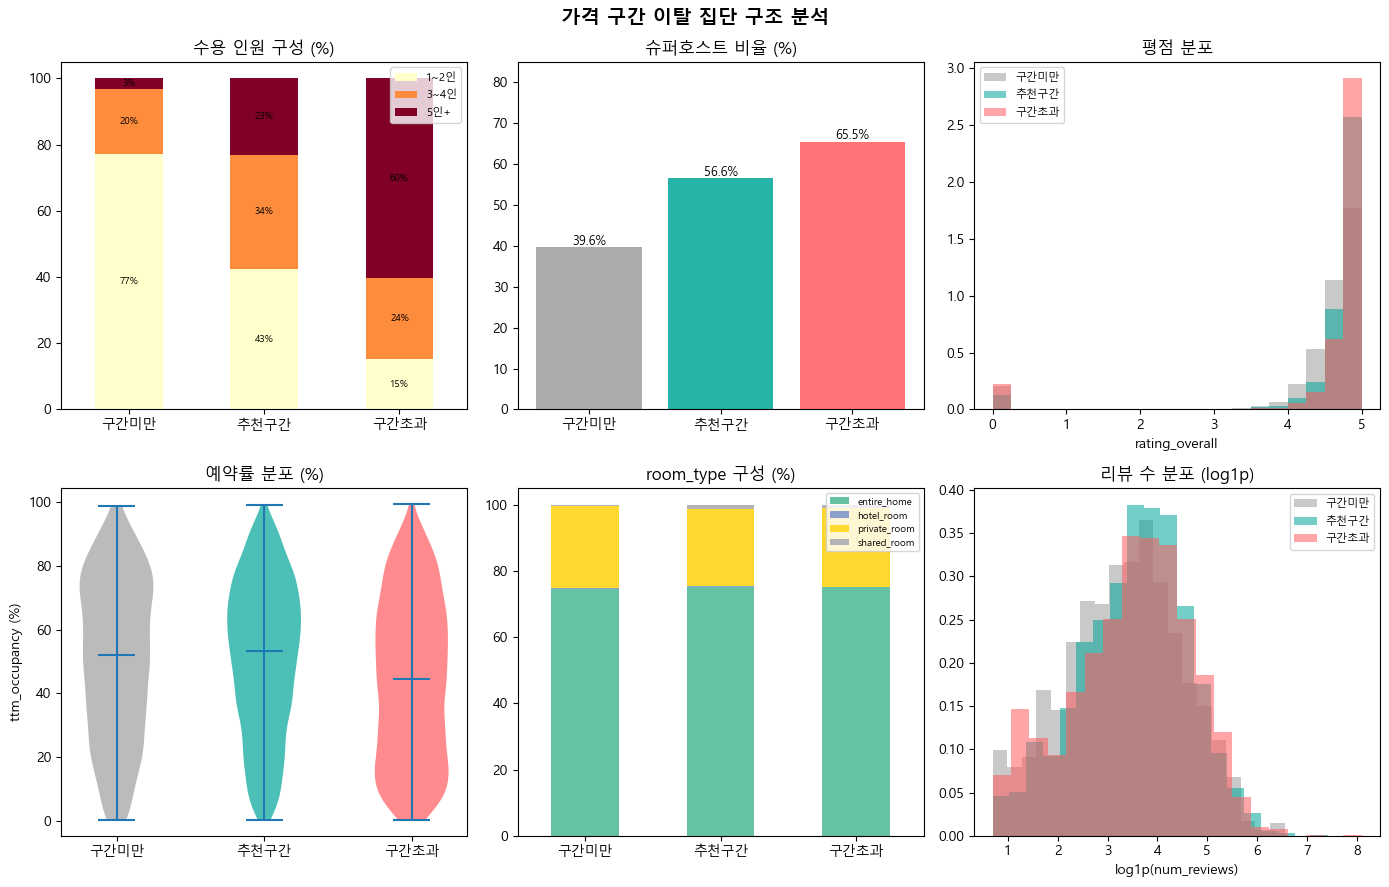

저장: reports/fig_10_deviation_structure.png


In [30]:
# ── 시각화 (2×3 구성)
grp_colors = {'구간미만': '#9E9E9E', '추천구간': '#00A699', '구간초과': '#FF5A5F'}

fig, axes = plt.subplots(2, 3, figsize=(14, 9))
fig.suptitle('가격 구간 이탈 집단 구조 분석', fontsize=14, fontweight='bold')

# [0,0] guests_group 누적 막대
ax = axes[0, 0]
gg_plot = pd.crosstab(grp['price_group'], grp['guests_group'], normalize='index') * 100
gg_plot = gg_plot.reindex(g_order)
gg_plot.plot(kind='bar', stacked=True, ax=ax, colormap='YlOrRd', legend=True)
ax.set_title('수용 인원 구성 (%)')
ax.set_xlabel('')
ax.tick_params(axis='x', rotation=0)
ax.legend(fontsize=8, loc='upper right')
for container in ax.containers:
    ax.bar_label(container, fmt='%.0f%%', label_type='center', fontsize=7)

# [0,1] 슈퍼호스트 비율 막대
ax = axes[0, 1]
sh_vals = [grp.loc[grp['price_group'] == g, 'superhost'].mean() * 100 for g in g_order]
bars = ax.bar(g_order, sh_vals, color=[grp_colors[g] for g in g_order], alpha=0.85)
for bar, v in zip(bars, sh_vals):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
            f'{v:.1f}%', ha='center', fontsize=9)
ax.set_title('슈퍼호스트 비율 (%)')
ax.set_ylim(0, 85)

# [0,2] 평점 분포
ax = axes[0, 2]
for g in g_order:
    sub = grp.loc[grp['price_group'] == g, 'rating_overall'].dropna()
    ax.hist(sub, bins=20, alpha=0.55, color=grp_colors[g], label=g, density=True)
ax.set_title('평점 분포')
ax.set_xlabel('rating_overall')
ax.legend(fontsize=8)

# [1,0] 예약률 violin
ax = axes[1, 0]
data_occ = [grp.loc[grp['price_group'] == g, 'ttm_occupancy'].dropna().values * 100
            for g in g_order]
parts = ax.violinplot(data_occ, positions=range(len(g_order)), showmedians=True)
for pc, g in zip(parts['bodies'], g_order):
    pc.set_facecolor(grp_colors[g])
    pc.set_alpha(0.7)
ax.set_xticks(range(len(g_order)))
ax.set_xticklabels(g_order)
ax.set_title('예약률 분포 (%)')
ax.set_ylabel('ttm_occupancy (%)')

# [1,1] room_type 구성 누적 막대
ax = axes[1, 1]
rt_plot = pd.crosstab(grp['price_group'], grp['room_type'], normalize='index') * 100
rt_plot = rt_plot.reindex(g_order)
rt_plot.plot(kind='bar', stacked=True, ax=ax, colormap='Set2', legend=True)
ax.set_title('room_type 구성 (%)')
ax.set_xlabel('')
ax.tick_params(axis='x', rotation=0)
ax.legend(fontsize=7, loc='upper right')

# [1,2] 리뷰 수 분포
ax = axes[1, 2]
for g in g_order:
    sub = grp.loc[grp['price_group'] == g, 'num_reviews'].dropna()
    ax.hist(np.log1p(sub), bins=20, alpha=0.55, color=grp_colors[g], label=g, density=True)
ax.set_title('리뷰 수 분포 (log1p)')
ax.set_xlabel('log1p(num_reviews)')
ax.legend(fontsize=8)

plt.tight_layout()
plt.savefig('../reports/fig_10_deviation_structure.png', dpi=100, bbox_inches='tight')
plt.show()
print('저장: reports/fig_10_deviation_structure.png')


In [31]:
# ── [4] 개선 시사점
print('=' * 62)
print('  [4] 개선 시사점')
print('=' * 62)

sh_b_v  = below['superhost'].mean() * 100
sh_m_v  = bench['superhost'].mean() * 100
sh_a_v  = above['superhost'].mean() * 100
g_b_v   = below['guests'].mean()
g_m_v   = bench['guests'].mean()
g_a_v   = above['guests'].mean()
gg_b_12 = gg_b.get('1~2인', 0)
gg_a_5p = gg_a.get('5인+', 0)
occ_b_v = below['ttm_occupancy'].mean() * 100
occ_m_v = bench['ttm_occupancy'].mean() * 100
occ_a_v = above['ttm_occupancy'].mean() * 100

print()
print('[ 1 ] 구간미만 구조에서 관찰되는 개선 가능 요소')
print('-' * 40)
print(f'수용 인원 1~2인 소형 숙소 {gg_b_12:.1f}% 집중 — 동일 district×room_type 내')
print(f'  대형 숙소 대비 낮은 ADR로 구간미만에 배치되는 구조가 관찰됨.')
print(f'슈퍼호스트 비율 {sh_b_v:.1f}% (추천구간 {sh_m_v:.1f}%) — 신뢰도 지표가 낮은 집단에서')
print(f'  저가 운영이 집중되는 패턴이 관찰됨.')
print(f'예약률 {occ_b_v:.1f}% vs 추천구간 {occ_m_v:.1f}% — 유의한 차이 미관찰.')
print(f'  저가 운영이 예약률 개선으로 이어지지 않을 가능성 검토 필요.')
print()
print('  개선 가능 방향 (데이터 기반):')
print('  - 슈퍼호스트 달성 경로 제공 → 신뢰도 지표 개선 후 요금 단계적 상향 가능성')
print('  - 소형 숙소(1~2인) 특화 벤치마크 기준 제공 검토')

print()
print('[ 2 ] 구간초과 구조에서 관찰되는 개선 가능 요소')
print('-' * 40)
print(f'수용 인원 5인+ 대형 숙소 {gg_a_5p:.1f}% 집중 — 대형 숙소가 동일 그룹 내에서')
print(f'  상위 ADR을 기록하며 구간초과에 배치되는 구조가 관찰됨.')
print(f'슈퍼호스트 비율 {sh_a_v:.1f}% (추천구간 {sh_m_v:.1f}%) — 품질 지표가 높은 집단.')
print(f'예약률 {occ_a_v:.1f}% — 추천구간 대비 낮으나 RevPAR는 최상위 수준 유지.')
print()
print('  개선 가능 방향 (데이터 기반):')
print('  - 구간초과(>p75) 집단에 대한 고가 전략 가이던스 추가 검토')
print('  - 예약률이 낮은 대형 숙소에 대한 수요 최적화 방안 검토 가능성')

print()
print('[ 3 ] 현행 벤치마크(district × room_type) 설계의 한계')
print('-' * 40)
print('현행 벤치마크는 district × room_type(69개 그룹)으로 요금 구간을 정의함.')
print('수용 인원(guests)은 벤치마크 기준에 포함되지 않음.')
print()
print(f'관찰된 패턴: guests_group × price_group χ²={chi2_gg:.1f}, p<0.001')
print(f'  구간미만 내 1~2인 {gg_b_12:.1f}%  ↔  구간초과 내 5인+ {gg_a_5p:.1f}%')
print()
print('  동일 district × room_type 그룹 내에서 소형/대형 숙소가 각각')
print('  하위/상위 가격대에 집중되는 구조적 편향이 관찰됨.')
print('  벤치마크를 district × room_type × guests_group으로 세분화할 경우')
print('  이 편향이 완화될 가능성이 있으나, 그룹 수 증가에 따른 표본 크기 감소 검토 필요.')
print('=' * 62)


  [4] 개선 시사점

[ 1 ] 구간미만 구조에서 관찰되는 개선 가능 요소
----------------------------------------
수용 인원 1~2인 소형 숙소 77.3% 집중 — 동일 district×room_type 내
  대형 숙소 대비 낮은 ADR로 구간미만에 배치되는 구조가 관찰됨.
슈퍼호스트 비율 39.6% (추천구간 56.6%) — 신뢰도 지표가 낮은 집단에서
  저가 운영이 집중되는 패턴이 관찰됨.
예약률 50.6% vs 추천구간 51.1% — 유의한 차이 미관찰.
  저가 운영이 예약률 개선으로 이어지지 않을 가능성 검토 필요.

  개선 가능 방향 (데이터 기반):
  - 슈퍼호스트 달성 경로 제공 → 신뢰도 지표 개선 후 요금 단계적 상향 가능성
  - 소형 숙소(1~2인) 특화 벤치마크 기준 제공 검토

[ 2 ] 구간초과 구조에서 관찰되는 개선 가능 요소
----------------------------------------
수용 인원 5인+ 대형 숙소 60.4% 집중 — 대형 숙소가 동일 그룹 내에서
  상위 ADR을 기록하며 구간초과에 배치되는 구조가 관찰됨.
슈퍼호스트 비율 65.5% (추천구간 56.6%) — 품질 지표가 높은 집단.
예약률 44.5% — 추천구간 대비 낮으나 RevPAR는 최상위 수준 유지.

  개선 가능 방향 (데이터 기반):
  - 구간초과(>p75) 집단에 대한 고가 전략 가이던스 추가 검토
  - 예약률이 낮은 대형 숙소에 대한 수요 최적화 방안 검토 가능성

[ 3 ] 현행 벤치마크(district × room_type) 설계의 한계
----------------------------------------
현행 벤치마크는 district × room_type(69개 그룹)으로 요금 구간을 정의함.
수용 인원(guests)은 벤치마크 기준에 포함되지 않음.

관찰된 패턴: guests_group × price_group χ²=2722.6, p<0.001
  구간미만 내 1~2인 7

---
## 3단계 추가: 방 개수(bedrooms_group) 가격 이탈 구조 분석

**분석 목적**: 방 개수가 가격 이탈 집단과 구조적으로 연결되어 있는지 확인한다.  
guests_group(수용 인원) 분석과 동일한 구조로 진행하여 비교한다.

| 그룹 | 기준 | Active+Operating 내 비중 |
|------|------|-------------------------|
| 1개이하 | bedrooms 0~1 (스튜디오·원룸) | 다수 |
| 2개    | bedrooms 2 | 중간 |
| 3개+   | bedrooms 3+ | 소수 |

In [32]:
# -- bedrooms_group 생성 (분석용 정의 -- features.csv의 Large/Normal과 별개)
BG_ORDER = ['1개이하', '2개', '3개+']
grp['bedrooms_group'] = pd.cut(
    grp['bedrooms'],
    bins=[-1, 1, 2, 100],
    labels=BG_ORDER
)

print('=' * 62)
print('  bedrooms_group 현황')
print('=' * 62)
print()

# ① 규모별 분포
bg_total = grp['bedrooms_group'].value_counts().reindex(BG_ORDER)
bg_pct   = grp['bedrooms_group'].value_counts(normalize=True).reindex(BG_ORDER) * 100
print('[ 전체 분포 ]')
for g in BG_ORDER:
    print(f'  {g:<8}: {int(bg_total[g]):>5,}개  ({bg_pct[g]:.1f}%)')
print(f'  합계   : {bg_total.sum():>5,}개')

# ② 가격그룹별 bedrooms_group 구성 (column normalize)
print()
print('[ bedrooms_group 분포 (각 가격그룹 내부 %) -- column normalize ]')
bg_col = pd.crosstab(grp['bedrooms_group'], grp['price_group'], normalize='columns') * 100
bg_col = bg_col.reindex(index=BG_ORDER, columns=g_order, fill_value=0)
bg_col['전체'] = grp['bedrooms_group'].value_counts(normalize=True).reindex(BG_ORDER) * 100
print(bg_col.round(1).to_string())

# ③ 각 bedrooms_group 내부에서 가격그룹 분포 (row normalize)
print()
print('[ 각 방개수 그룹 내부 가격그룹 분포 (%) -- row normalize ]')
bg_row = pd.crosstab(grp['bedrooms_group'], grp['price_group'], normalize='index') * 100
bg_row = bg_row.reindex(index=BG_ORDER, columns=g_order, fill_value=0)
print(bg_row.round(1).to_string())

# ④ 실제 건수
print()
print('[ 실제 건수 ]')
bg_cnt = pd.crosstab(grp['bedrooms_group'], grp['price_group'])
bg_cnt = bg_cnt.reindex(index=BG_ORDER, columns=g_order, fill_value=0)
print(bg_cnt.to_string())

# ⑤ 카이제곱 + Cramér's V
from scipy.stats import chi2_contingency
chi2_bg, p_bg, dof_bg, _ = chi2_contingency(bg_cnt.values)
n_bg = bg_cnt.values.sum()
r_bg, k_bg = bg_cnt.shape
v_bg = np.sqrt(chi2_bg / (n_bg * (min(r_bg, k_bg) - 1)))
print()
print('[ 카이제곱 검정 ]')
print(f'  chi2       = {chi2_bg:.3f}')
print(f'  df         = {dof_bg}')
print(f'  p-value    = {p_bg:.2e}')
print(f"  Cramér's V = {v_bg:.4f}")

# ⑥ 패턴 요약
print()
print('[ 패턴 요약 ]')
below_bg = grp.loc[grp['price_group'] == '구간미만', 'bedrooms_group'].value_counts(normalize=True) * 100
bench_bg = grp.loc[grp['price_group'] == '추천구간', 'bedrooms_group'].value_counts(normalize=True) * 100
above_bg = grp.loc[grp['price_group'] == '구간초과', 'bedrooms_group'].value_counts(normalize=True) * 100
for g in BG_ORDER:
    b = below_bg.get(g, 0.0)
    m = bench_bg.get(g, 0.0)
    a = above_bg.get(g, 0.0)
    print(f'  {g:<8}: 구간미만 {b:.1f}%  /  추천구간 {m:.1f}%  /  구간초과 {a:.1f}%')


  bedrooms_group 현황

[ 전체 분포 ]
  1개이하    : 9,541개  (66.3%)
  2개      : 3,126개  (21.7%)
  3개+     : 1,732개  (12.0%)
  합계   : 14,399개

[ bedrooms_group 분포 (각 가격그룹 내부 %) -- column normalize ]
price_group     구간미만  추천구간  구간초과    전체
bedrooms_group                        
1개이하            93.6  70.8  39.7  66.3
2개               5.3  23.3  27.1  21.7
3개+              1.0   5.9  33.2  12.0

[ 각 방개수 그룹 내부 가격그룹 분포 (%) -- row normalize ]
price_group     구간미만  추천구간  구간초과
bedrooms_group                  
1개이하            19.9  65.1  15.0
2개               3.5  65.4  31.2
3개+              1.2  29.7  69.1

[ 실제 건수 ]
price_group     구간미만  추천구간  구간초과
bedrooms_group                  
1개이하            1897  6214  1430
2개               108  2043   975
3개+               21   514  1197

[ 카이제곱 검정 ]
  chi2       = 2775.726
  df         = 4
  p-value    = 0.00e+00
  Cramér's V = 0.3105

[ 패턴 요약 ]
  1개이하    : 구간미만 93.6%  /  추천구간 70.8%  /  구간초과 39.7%
  2개      : 구간미만 5.3%  /  추천구간 23.3%  /  구간초과 27.1%
  3개+     : 구

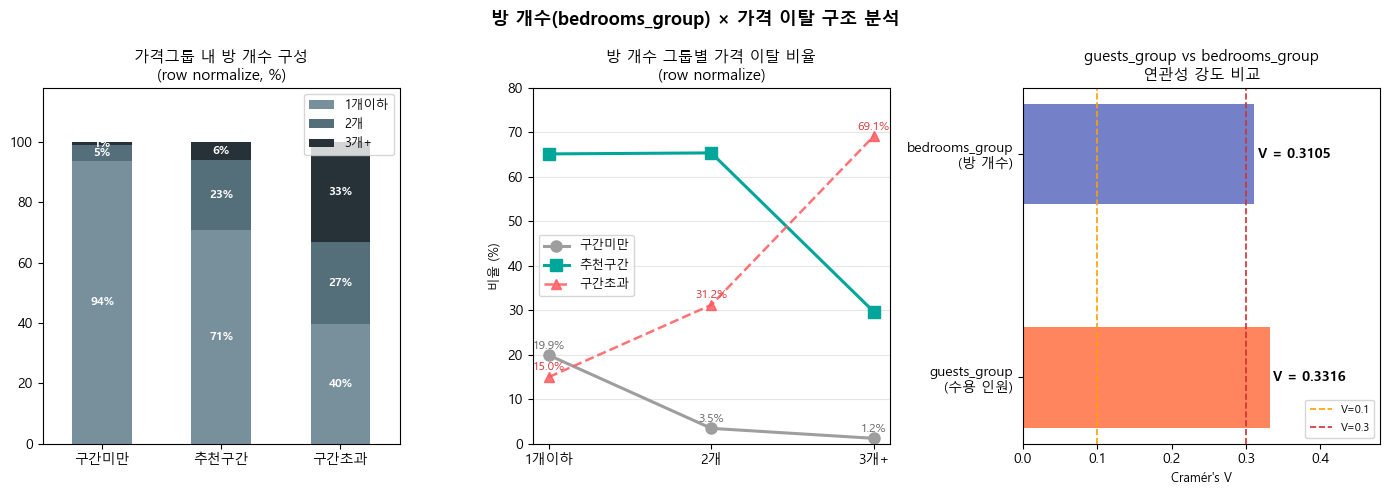

저장: reports/fig_10_bedrooms_deviation.png


In [33]:
# -- bedrooms_group 시각화 (1×3)
# v_gg2: guests_group Cramér's V (grp에 guests_group 이미 존재 — cell 30)
from scipy.stats import chi2_contingency as _chi2

def _v(ct):
    chi2, _, _, _ = _chi2(ct.values)
    n = ct.values.sum()
    r, k = ct.shape
    return float(np.sqrt(chi2 / (n * (min(r, k) - 1))))

_gg_cnt = pd.crosstab(grp['guests_group'], grp['price_group'])
_gg_cnt = _gg_cnt.reindex(index=['1~2인','3~4인','5인+'], columns=g_order, fill_value=0)
_v_gg2  = _v(_gg_cnt)

fig, axes = plt.subplots(1, 3, figsize=(14, 5))
fig.suptitle('방 개수(bedrooms_group) × 가격 이탈 구조 분석', fontsize=13, fontweight='bold')

# [0] 누적 막대: 가격그룹별 bedrooms_group 구성
ax = axes[0]
bg_plot = pd.crosstab(grp['price_group'], grp['bedrooms_group'], normalize='index') * 100
bg_plot = bg_plot.reindex(g_order)
bg_plot.plot(kind='bar', stacked=True, ax=ax,
             color=['#78909C', '#546E7A', '#263238'], legend=True)
ax.set_title('가격그룹 내 방 개수 구성\n(row normalize, %)', fontsize=11)
ax.set_xlabel('')
ax.tick_params(axis='x', rotation=0)
ax.set_ylim(0, 118)
ax.legend(fontsize=9, loc='upper right')
for container in ax.containers:
    ax.bar_label(container, fmt='%.0f%%', label_type='center',
                 fontsize=8.5, color='white', fontweight='bold')

# [1] 선 그래프: bedrooms_group별 구간미만·추천구간·구간초과 비율
ax = axes[1]
x_pos = list(range(len(BG_ORDER)))
below_vals_bg = [grp.loc[(grp['bedrooms_group']==g) & (grp['price_group']=='구간미만')].shape[0] /
                 max(grp.loc[grp['bedrooms_group']==g].shape[0], 1) * 100 for g in BG_ORDER]
bench_vals_bg = [grp.loc[(grp['bedrooms_group']==g) & (grp['price_group']=='추천구간')].shape[0] /
                 max(grp.loc[grp['bedrooms_group']==g].shape[0], 1) * 100 for g in BG_ORDER]
above_vals_bg = [grp.loc[(grp['bedrooms_group']==g) & (grp['price_group']=='구간초과')].shape[0] /
                 max(grp.loc[grp['bedrooms_group']==g].shape[0], 1) * 100 for g in BG_ORDER]
ax.plot(x_pos, below_vals_bg, 'o-',  color='#9E9E9E', linewidth=2.2, markersize=8, label='구간미만')
ax.plot(x_pos, bench_vals_bg, 's-',  color='#00A699', linewidth=2.2, markersize=8, label='추천구간')
ax.plot(x_pos, above_vals_bg, '^--', color='#FF5A5F', linewidth=1.8, markersize=7,
        alpha=0.85, label='구간초과')
for i, (b, a) in enumerate(zip(below_vals_bg, above_vals_bg)):
    ax.text(i, b + 1.5, f'{b:.1f}%', ha='center', fontsize=8.5, color='#616161')
    ax.text(i, a + 1.5, f'{a:.1f}%', ha='center', fontsize=8.5, color='#D32F2F')
ax.set_xticks(x_pos)
ax.set_xticklabels(BG_ORDER, fontsize=10)
ax.set_ylabel('비율 (%)', fontsize=9)
ax.set_ylim(0, 80)
ax.set_title('방 개수 그룹별 가격 이탈 비율\n(row normalize)', fontsize=11)
ax.legend(fontsize=9)
ax.grid(axis='y', alpha=0.3)

# [2] guests_group vs bedrooms_group Cramér's V 비교
ax = axes[2]
compare_labels = ['guests_group\n(수용 인원)', 'bedrooms_group\n(방 개수)']
compare_v      = [_v_gg2, v_bg]
compare_colors = ['#FF7043', '#5C6BC0']
bars_cmp = ax.barh(compare_labels, compare_v, color=compare_colors, alpha=0.85, height=0.45)
ax.axvline(0.1, color='#FFA000', linestyle='--', linewidth=1.2, label='V=0.1')
ax.axvline(0.3, color='#D32F2F', linestyle='--', linewidth=1.2, label='V=0.3')
for bar, v in zip(bars_cmp, compare_v):
    ax.text(v + 0.005, bar.get_y() + bar.get_height()/2,
            f'V = {v:.4f}', va='center', fontsize=10, fontweight='bold')
ax.set_xlim(0, 0.48)
ax.set_xlabel("Cramér's V", fontsize=9)
ax.set_title("guests_group vs bedrooms_group\n연관성 강도 비교", fontsize=11)
ax.legend(fontsize=8, loc='lower right')

plt.tight_layout()
plt.savefig('../reports/fig_10_bedrooms_deviation.png', dpi=100, bbox_inches='tight')
plt.show()
print('저장: reports/fig_10_bedrooms_deviation.png')


---
# 4단계: 가격 이탈과 등급·규모의 구조적 연관성 검증

**분석 목적**: 가격 이탈(구간미만 / 추천구간 / 구간초과)이 호스트 등급 및 수용 인원 그룹과
구조적으로 연결되어 있는지 교차 구조 중심으로 검증한다.  
단순 평균 비교가 아닌 교차 분포 + 카이제곱 검정 기반 분석.

| 분석 | 내용 |
|------|------|
| 1-A | price_group × host_grade — column/row normalize + 카이제곱 + Cramér's V |
| 1-B | price_group × guests_group — 동일 구조 |
| 2   | host_grade × guests_group × price_group (3중 구조) |
| 3   | 등급 통제 후 가격 이탈 비율 |
| 4   | 규모 통제 후 가격 이탈 비율 |
| 5   | 연관성 강도 + 이탈 잔존 여부 + 벤치마크 한계 정리 |

In [34]:
# -- 공통 유틸리티
from scipy.stats import chi2_contingency

def cramers_v(ct_df):
    """카이제곱 + Cramer's V 반환. ct_df: pd.DataFrame (crosstab 결과)"""
    ct = ct_df.values
    chi2, p, dof, _ = chi2_contingency(ct)
    n = ct.sum()
    r, k = ct.shape
    v = np.sqrt(chi2 / (n * (min(r, k) - 1)))
    return chi2, p, dof, v

# -- 분석용 순서 정의 (기존 변수 재사용)
G_ORDER  = ['구간미만', '추천구간', '구간초과']
GH_ORDER = ['신규', '안정', '프리미엄']
GG_ORDER = ['1~2인', '3~4인', '5인+']

# host_grade 유효 서브셋
grp_h = grp[grp['host_grade'].isin(GH_ORDER)].copy()

# ──────────────────────────────────────────────────────────
print('=' * 70)
print('  1-A  2중 교차 분석: price_group x host_grade')
print('=' * 70)

# 실제 건수
ct_hg_cnt = pd.crosstab(grp_h['host_grade'], grp_h['price_group'])
ct_hg_cnt = ct_hg_cnt.reindex(index=GH_ORDER, columns=G_ORDER, fill_value=0)
print('\n[실제 건수]')
print(ct_hg_cnt.to_string())

# Column normalize: 각 가격그룹 내부에서 등급 분포 (%)
ct_hg_col = pd.crosstab(
    grp_h['host_grade'], grp_h['price_group'], normalize='columns'
) * 100
ct_hg_col = ct_hg_col.reindex(index=GH_ORDER, columns=G_ORDER, fill_value=0)
print('\n[각 가격그룹 내부에서 등급 분포 (%) -- column normalize]')
print(ct_hg_col.round(1).to_string())

# Row normalize: 각 등급 내부에서 가격그룹 분포 (%)
ct_hg_row = pd.crosstab(
    grp_h['host_grade'], grp_h['price_group'], normalize='index'
) * 100
ct_hg_row = ct_hg_row.reindex(index=GH_ORDER, columns=G_ORDER, fill_value=0)
print('\n[각 등급 내부에서 가격그룹 분포 (%) -- row normalize]')
print(ct_hg_row.round(1).to_string())

# 카이제곱 + Cramer's V
chi2_hg, p_hg, dof_hg, v_hg = cramers_v(ct_hg_cnt)
print("\n[카이제곱 검정]")
print(f"  chi2       = {chi2_hg:.3f}")
print(f"  df         = {dof_hg}")
print(f"  p-value    = {p_hg:.2e}")
print(f"  Cramer's V = {v_hg:.4f}")


  1-A  2중 교차 분석: price_group x host_grade

[실제 건수]
price_group  구간미만  추천구간  구간초과
host_grade                   
신규            741  1894   806
안정           1033  4959  1842
프리미엄          252  1918   954

[각 가격그룹 내부에서 등급 분포 (%) -- column normalize]
price_group  구간미만  추천구간  구간초과
host_grade                   
신규           36.6  21.6  22.4
안정           51.0  56.5  51.1
프리미엄         12.4  21.9  26.5

[각 등급 내부에서 가격그룹 분포 (%) -- row normalize]
price_group  구간미만  추천구간  구간초과
host_grade                   
신규           21.5  55.0  23.4
안정           13.2  63.3  23.5
프리미엄          8.1  61.4  30.5

[카이제곱 검정]
  chi2       = 296.196
  df         = 4
  p-value    = 7.17e-63
  Cramer's V = 0.1014


In [35]:
# ──────────────────────────────────────────────────────────
print('=' * 70)
print('  1-B  2중 교차 분석: price_group x guests_group')
print('=' * 70)

# 실제 건수
ct_gg_cnt = pd.crosstab(grp['guests_group'], grp['price_group'])
ct_gg_cnt = ct_gg_cnt.reindex(index=GG_ORDER, columns=G_ORDER, fill_value=0)
print('\n[실제 건수]')
print(ct_gg_cnt.to_string())

# Column normalize: 각 가격그룹 내부에서 guests_group 분포 (%)
ct_gg_col = pd.crosstab(
    grp['guests_group'], grp['price_group'], normalize='columns'
) * 100
ct_gg_col = ct_gg_col.reindex(index=GG_ORDER, columns=G_ORDER, fill_value=0)
print('\n[각 가격그룹 내부에서 guests_group 분포 (%) -- column normalize]')
print(ct_gg_col.round(1).to_string())

# Row normalize: 각 guests_group 내부에서 가격그룹 분포 (%)
ct_gg_row = pd.crosstab(
    grp['guests_group'], grp['price_group'], normalize='index'
) * 100
ct_gg_row = ct_gg_row.reindex(index=GG_ORDER, columns=G_ORDER, fill_value=0)
print('\n[각 guests_group 내부에서 가격그룹 분포 (%) -- row normalize]')
print(ct_gg_row.round(1).to_string())

# 카이제곱 + Cramer's V
chi2_gg2, p_gg2, dof_gg2, v_gg2 = cramers_v(ct_gg_cnt)
print("\n[카이제곱 검정]")
print(f"  chi2       = {chi2_gg2:.3f}")
print(f"  df         = {dof_gg2}")
print(f"  p-value    = {p_gg2:.2e}")
print(f"  Cramer's V = {v_gg2:.4f}")


  1-B  2중 교차 분석: price_group x guests_group

[실제 건수]
price_group   구간미만  추천구간  구간초과
guests_group                  
1~2인          1278  3185   493
3~4인           324  2565   790
5인+             51  1737  1956

[각 가격그룹 내부에서 guests_group 분포 (%) -- column normalize]
price_group   구간미만  추천구간  구간초과
guests_group                  
1~2인          77.3  42.5  15.2
3~4인          19.6  34.3  24.4
5인+            3.1  23.2  60.4

[각 guests_group 내부에서 가격그룹 분포 (%) -- row normalize]
price_group   구간미만  추천구간  구간초과
guests_group                  
1~2인          25.8  64.3   9.9
3~4인           8.8  69.7  21.5
5인+            1.4  46.4  52.2

[카이제곱 검정]
  chi2       = 2722.636
  df         = 4
  p-value    = 0.00e+00
  Cramer's V = 0.3316


In [36]:
# ──────────────────────────────────────────────────────────
print('=' * 70)
print('  2  3중 구조: host_grade x guests_group x price_group')
print('=' * 70)
print()
print('각 host_grade 내부에서, guests_group별 가격그룹 분포 (%)')
print('  * 표본 수 30개 미만 조합은 [*n=XX] 표시')
print()

sep = '  ' + '-' * 58

for grade in GH_ORDER:
    sub_g = grp_h[grp_h['host_grade'] == grade]
    print(f'[ {grade} 등급 ]  (전체 n={len(sub_g):,})')
    print(f'  {"guests_group":<10} | {"구간미만":>8} | {"추천구간":>8} | {"구간초과":>8} | {"n":>6}')
    print(sep)
    for gg in GG_ORDER:
        sub_gg = sub_g[sub_g['guests_group'] == gg]
        n_gg = len(sub_gg)
        if n_gg == 0:
            print(f'  {gg:<10} |  (데이터 없음)')
            continue
        pct   = sub_gg['price_group'].value_counts(normalize=True) * 100
        b_pct = pct.get('구간미만', 0.0)
        m_pct = pct.get('추천구간', 0.0)
        a_pct = pct.get('구간초과', 0.0)
        flag  = f'  [*n={n_gg}]' if n_gg < 30 else ''
        print(f'  {gg:<10} | {b_pct:>7.1f}% | {m_pct:>7.1f}% | {a_pct:>7.1f}% | {n_gg:>5}{flag}')
    print()


  2  3중 구조: host_grade x guests_group x price_group

각 host_grade 내부에서, guests_group별 가격그룹 분포 (%)
  * 표본 수 30개 미만 조합은 [*n=XX] 표시

[ 신규 등급 ]  (전체 n=3,441)
  guests_group |     구간미만 |     추천구간 |     구간초과 |      n
  ----------------------------------------------------------
  1~2인       |    31.8% |    55.0% |    13.2% |  1467
  3~4인       |     9.5% |    63.7% |    26.9% |   677
  5인+        |     2.7% |    45.0% |    52.3% |   587

[ 안정 등급 ]  (전체 n=7,834)
  guests_group |     구간미만 |     추천구간 |     구간초과 |      n
  ----------------------------------------------------------
  1~2인       |    25.6% |    66.7% |     7.8% |  2567
  3~4인       |     8.5% |    71.8% |    19.7% |  2119
  5인+        |     1.3% |    49.3% |    49.3% |  2106

[ 프리미엄 등급 ]  (전체 n=3,124)
  guests_group |     구간미만 |     추천구간 |     구간초과 |      n
  ----------------------------------------------------------
  1~2인       |    16.8% |    72.3% |    10.8% |   922
  3~4인       |     8.9% |    69.4% |    21.6% |   883
  5인+   

In [37]:
# ──────────────────────────────────────────────────────────
print('=' * 70)
print('  3  등급 통제 후 가격 이탈 존재 여부')
print('=' * 70)
print()
print('각 host_grade 내부에서 가격그룹 분포 (%)')
print()

hdr_h = f'  {"host_grade":<10} | {"구간미만":>8} | {"추천구간":>8} | {"구간초과":>8} | {"합계 n":>8}'
print(hdr_h)
print('  ' + '-' * 54)

grade_deviation = {}
for grade in GH_ORDER:
    sub = grp_h[grp_h['host_grade'] == grade]
    n   = len(sub)
    pct = sub['price_group'].value_counts(normalize=True) * 100
    b   = pct.get('구간미만', 0.0)
    m   = pct.get('추천구간', 0.0)
    a   = pct.get('구간초과', 0.0)
    grade_deviation[grade] = {'below': b, 'bench': m, 'above': a, 'n': n}
    print(f'  {grade:<10} | {b:>7.1f}% | {m:>7.1f}% | {a:>7.1f}% | {n:>7,}')

print()
prem_b = grade_deviation['프리미엄']['below']
prem_a = grade_deviation['프리미엄']['above']
new_b  = grade_deviation['신규']['below']
new_a  = grade_deviation['신규']['above']
print(f'확인 포인트:')
print(f'  프리미엄 등급 내 구간미만: {prem_b:.1f}%  -- ' + ('이탈 잔존 확인됨' if prem_b > 0 else '없음'))
print(f'  프리미엄 등급 내 구간초과: {prem_a:.1f}%')
print(f'  신규 등급 내 구간미만:     {new_b:.1f}%')
print(f'  신규 등급 내 구간초과:     {new_a:.1f}%  -- ' + ('이탈 잔존 확인됨' if new_a > 0 else '없음'))

# ──────────────────────────────────────────────────────────
print()
print('=' * 70)
print('  4  규모 통제 후 가격 이탈 존재 여부')
print('=' * 70)
print()
print('각 guests_group 내부에서 가격그룹 분포 (%)')
print()

hdr_g = f'  {"guests_group":<10} | {"구간미만":>8} | {"추천구간":>8} | {"구간초과":>8} | {"합계 n":>8}'
print(hdr_g)
print('  ' + '-' * 54)

gg_deviation = {}
for gg in GG_ORDER:
    sub = grp[grp['guests_group'] == gg]
    n   = len(sub)
    pct = sub['price_group'].value_counts(normalize=True) * 100
    b   = pct.get('구간미만', 0.0)
    m   = pct.get('추천구간', 0.0)
    a   = pct.get('구간초과', 0.0)
    gg_deviation[gg] = {'below': b, 'bench': m, 'above': a, 'n': n}
    print(f'  {gg:<10} | {b:>7.1f}% | {m:>7.1f}% | {a:>7.1f}% | {n:>7,}')

print()
print('확인 포인트:')
for gg in GG_ORDER:
    b = gg_deviation[gg]['below']
    a = gg_deviation[gg]['above']
    print(f'  {gg}: 구간미만 {b:.1f}%  /  구간초과 {a:.1f}%')


  3  등급 통제 후 가격 이탈 존재 여부

각 host_grade 내부에서 가격그룹 분포 (%)

  host_grade |     구간미만 |     추천구간 |     구간초과 |     합계 n
  ------------------------------------------------------


  신규         |    21.5% |    55.0% |    23.4% |   3,441
  안정         |    13.2% |    63.3% |    23.5% |   7,834
  프리미엄       |     8.1% |    61.4% |    30.5% |   3,124

확인 포인트:
  프리미엄 등급 내 구간미만: 8.1%  -- 이탈 잔존 확인됨
  프리미엄 등급 내 구간초과: 30.5%
  신규 등급 내 구간미만:     21.5%
  신규 등급 내 구간초과:     23.4%  -- 이탈 잔존 확인됨

  4  규모 통제 후 가격 이탈 존재 여부

각 guests_group 내부에서 가격그룹 분포 (%)

  guests_group |     구간미만 |     추천구간 |     구간초과 |     합계 n
  ------------------------------------------------------
  1~2인       |    25.8% |    64.3% |     9.9% |   4,956
  3~4인       |     8.8% |    69.7% |    21.5% |   3,679
  5인+        |     1.4% |    46.4% |    52.2% |   3,744

확인 포인트:
  1~2인: 구간미만 25.8%  /  구간초과 9.9%
  3~4인: 구간미만 8.8%  /  구간초과 21.5%
  5인+: 구간미만 1.4%  /  구간초과 52.2%


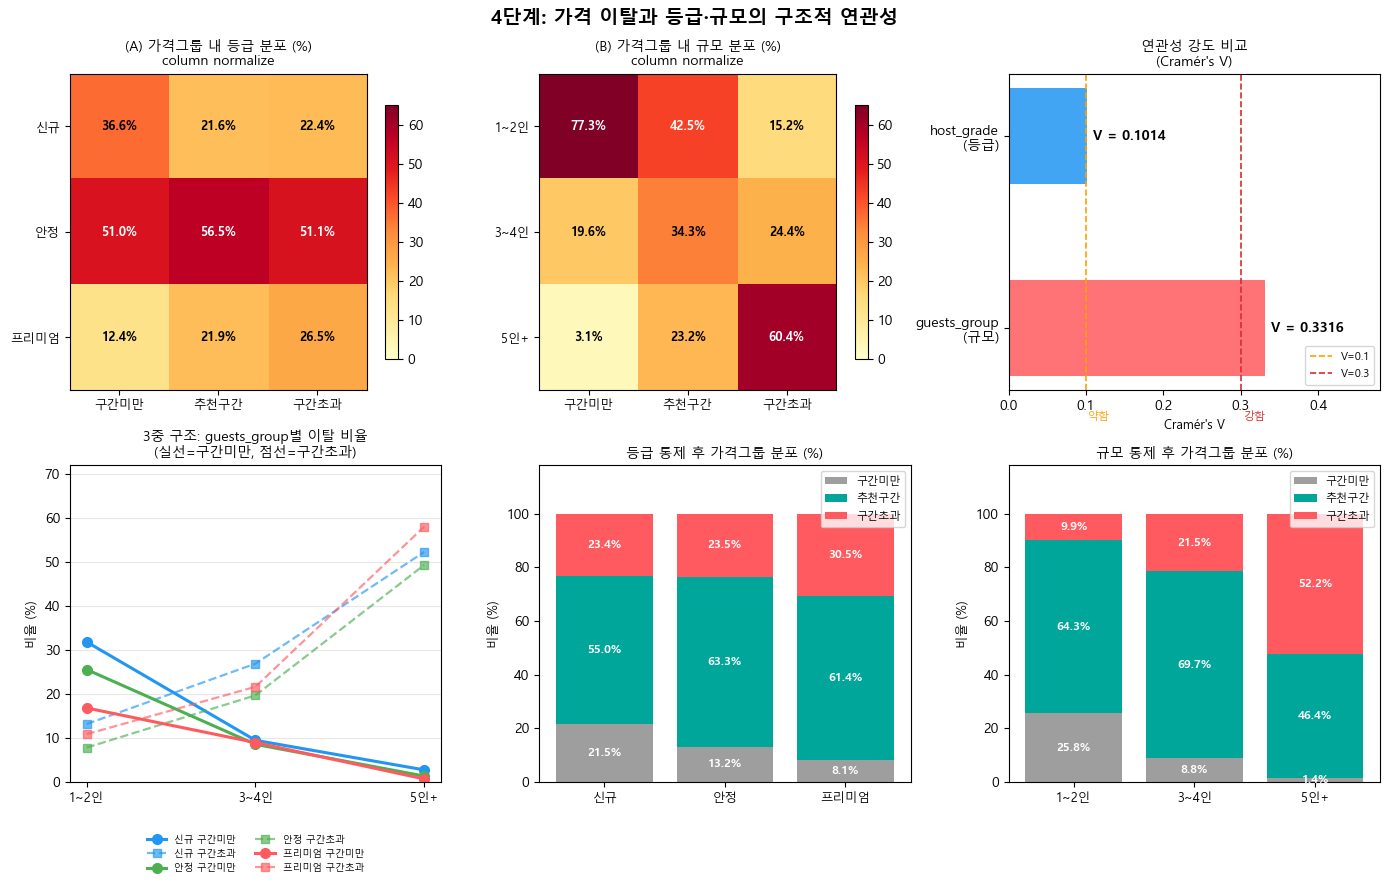

저장: reports/fig_10_deviation_crosssection.png


In [38]:
# ── 4단계 시각화 (2×3)
# 사용 변수: ct_hg_col, ct_gg_col (cell 37,38), v_hg, v_gg2 (cell 37,38)
#            grade_deviation, gg_deviation, GH_ORDER, GG_ORDER, G_ORDER (cell 40)
# 3중 구조 재계산 (grp_h 사용)

grade_colors_3way = {'신규': '#2196F3', '안정': '#4CAF50', '프리미엄': '#FF5A5F'}
stacked_colors    = {'구간미만': '#9E9E9E', '추천구간': '#00A699', '구간초과': '#FF5A5F'}

fig, axes = plt.subplots(2, 3, figsize=(14, 9))
fig.suptitle('4단계: 가격 이탈과 등급·규모의 구조적 연관성', fontsize=14, fontweight='bold')

# ── [0,0] Heatmap A: 가격그룹 내 등급 분포 (column normalize)
ax = axes[0, 0]
data_a = ct_hg_col.values
im0 = ax.imshow(data_a, cmap='YlOrRd', aspect='auto', vmin=0, vmax=65)
ax.set_xticks(range(len(G_ORDER)));  ax.set_xticklabels(G_ORDER, fontsize=9)
ax.set_yticks(range(len(GH_ORDER))); ax.set_yticklabels(GH_ORDER, fontsize=9)
ax.set_title('(A) 가격그룹 내 등급 분포 (%)\ncolumn normalize', fontsize=10)
for i in range(len(GH_ORDER)):
    for j in range(len(G_ORDER)):
        v = data_a[i, j]
        ax.text(j, i, f'{v:.1f}%', ha='center', va='center',
                fontsize=9, color='white' if v > 42 else 'black', fontweight='bold')
plt.colorbar(im0, ax=ax, shrink=0.8)

# ── [0,1] Heatmap B: 가격그룹 내 규모 분포 (column normalize)
ax = axes[0, 1]
data_b = ct_gg_col.values
im1 = ax.imshow(data_b, cmap='YlOrRd', aspect='auto', vmin=0, vmax=65)
ax.set_xticks(range(len(G_ORDER)));  ax.set_xticklabels(G_ORDER, fontsize=9)
ax.set_yticks(range(len(GG_ORDER))); ax.set_yticklabels(GG_ORDER, fontsize=9)
ax.set_title('(B) 가격그룹 내 규모 분포 (%)\ncolumn normalize', fontsize=10)
for i in range(len(GG_ORDER)):
    for j in range(len(G_ORDER)):
        v = data_b[i, j]
        ax.text(j, i, f'{v:.1f}%', ha='center', va='center',
                fontsize=9, color='white' if v > 42 else 'black', fontweight='bold')
plt.colorbar(im1, ax=ax, shrink=0.8)

# ── [0,2] Cramér's V 수평 막대 비교
ax = axes[0, 2]
labels_v = ['guests_group\n(규모)', 'host_grade\n(등급)']
v_vals   = [v_gg2, v_hg]
bar_cols = ['#FF5A5F', '#2196F3']
bars_v = ax.barh(labels_v, v_vals, color=bar_cols, alpha=0.85, height=0.5)
ax.axvline(0.1, color='#FFA000', linestyle='--', linewidth=1.2, label='V=0.1')
ax.axvline(0.3, color='#D32F2F', linestyle='--', linewidth=1.2, label='V=0.3')
for bar, v in zip(bars_v, v_vals):
    ax.text(v + 0.008, bar.get_y() + bar.get_height() / 2,
            f'V = {v:.4f}', va='center', fontsize=10, fontweight='bold')
ax.text(0.103, -0.48, '약함', fontsize=8, color='#FFA000')
ax.text(0.303, -0.48, '강함', fontsize=8, color='#D32F2F')
ax.set_xlim(0, 0.48)
ax.set_xlabel("Cramér's V", fontsize=9)
ax.set_title("연관성 강도 비교\n(Cramér's V)", fontsize=10)
ax.legend(fontsize=8, loc='lower right')

# ── [1,0] 3중 구조: guests_group별 이탈 비율 (등급별 선)
ax = axes[1, 0]
x_pos = list(range(len(GG_ORDER)))
for grade in GH_ORDER:
    sub_g = grp_h[grp_h['host_grade'] == grade]
    below_line, above_line = [], []
    for gg in GG_ORDER:
        sub_gg = sub_g[sub_g['guests_group'] == gg]
        pct = sub_gg['price_group'].value_counts(normalize=True) * 100
        below_line.append(pct.get('구간미만', 0.0))
        above_line.append(pct.get('구간초과', 0.0))
    c = grade_colors_3way[grade]
    ax.plot(x_pos, below_line, 'o-',  color=c, linewidth=2.2, markersize=7,
            label=f'{grade} 구간미만')
    ax.plot(x_pos, above_line, 's--', color=c, linewidth=1.6, markersize=6,
            alpha=0.65, label=f'{grade} 구간초과')
ax.set_xticks(x_pos)
ax.set_xticklabels(GG_ORDER, fontsize=9)
ax.set_ylabel('비율 (%)', fontsize=9)
ax.set_ylim(0, 72)
ax.set_title('3중 구조: guests_group별 이탈 비율\n(실선=구간미만, 점선=구간초과)', fontsize=10)
ax.legend(fontsize=7, ncol=2, loc='upper center', bbox_to_anchor=(0.5, -0.14), frameon=False)
ax.grid(axis='y', alpha=0.3)

# ── [1,1] 등급 통제 누적 막대
ax = axes[1, 1]
b_h = [grade_deviation[g]['below'] for g in GH_ORDER]
m_h = [grade_deviation[g]['bench'] for g in GH_ORDER]
a_h = [grade_deviation[g]['above'] for g in GH_ORDER]
x3  = list(range(len(GH_ORDER)))
ax.bar(x3, b_h, color='#9E9E9E', label='구간미만')
ax.bar(x3, m_h, bottom=b_h, color='#00A699', label='추천구간')
ax.bar(x3, a_h, bottom=[b+m for b,m in zip(b_h, m_h)], color='#FF5A5F', label='구간초과')
ax.set_xticks(x3)
ax.set_xticklabels(GH_ORDER, fontsize=9)
ax.set_ylim(0, 118)
ax.set_ylabel('비율 (%)', fontsize=9)
ax.set_title('등급 통제 후 가격그룹 분포 (%)', fontsize=10)
ax.legend(fontsize=8, loc='upper right')
for i, (b, m, a) in enumerate(zip(b_h, m_h, a_h)):
    ax.text(i, b/2,       f'{b:.1f}%', ha='center', va='center', fontsize=8.5, color='white', fontweight='bold')
    ax.text(i, b+m/2,     f'{m:.1f}%', ha='center', va='center', fontsize=8.5, color='white', fontweight='bold')
    ax.text(i, b+m+a/2,   f'{a:.1f}%', ha='center', va='center', fontsize=8.5, color='white', fontweight='bold')

# ── [1,2] 규모 통제 누적 막대
ax = axes[1, 2]
b_g = [gg_deviation[gg]['below'] for gg in GG_ORDER]
m_g = [gg_deviation[gg]['bench'] for gg in GG_ORDER]
a_g = [gg_deviation[gg]['above'] for gg in GG_ORDER]
x4  = list(range(len(GG_ORDER)))
ax.bar(x4, b_g, color='#9E9E9E', label='구간미만')
ax.bar(x4, m_g, bottom=b_g, color='#00A699', label='추천구간')
ax.bar(x4, a_g, bottom=[b+m for b,m in zip(b_g, m_g)], color='#FF5A5F', label='구간초과')
ax.set_xticks(x4)
ax.set_xticklabels(GG_ORDER, fontsize=9)
ax.set_ylim(0, 118)
ax.set_ylabel('비율 (%)', fontsize=9)
ax.set_title('규모 통제 후 가격그룹 분포 (%)', fontsize=10)
ax.legend(fontsize=8, loc='upper right')
for i, (b, m, a) in enumerate(zip(b_g, m_g, a_g)):
    ax.text(i, b/2,       f'{b:.1f}%', ha='center', va='center', fontsize=8.5, color='white', fontweight='bold')
    ax.text(i, b+m/2,     f'{m:.1f}%', ha='center', va='center', fontsize=8.5, color='white', fontweight='bold')
    ax.text(i, b+m+a/2,   f'{a:.1f}%', ha='center', va='center', fontsize=8.5, color='white', fontweight='bold')

plt.tight_layout()
plt.savefig('../reports/fig_10_deviation_crosssection.png', dpi=100, bbox_inches='tight')
plt.show()
print('저장: reports/fig_10_deviation_crosssection.png')

In [39]:
# ──────────────────────────────────────────────────────────
print('=' * 70)
print('  5  결과 해석 정리')
print('=' * 70)

def v_label(v):
    if v < 0.1:   return '약함 (V<0.1)'
    elif v < 0.2: return '소 (0.1≤V<0.2)'
    elif v < 0.3: return '중 (0.2≤V<0.3)'
    else:         return '강 (V≥0.3)'

print()
print('[1] 가격 이탈과 등급(host_grade)의 연관성 강도')
print(f'  chi2={chi2_hg:.1f}, df={dof_hg}, p={p_hg:.2e}, Cramer V={v_hg:.4f}')
print(f'  -> 효과 크기: {v_label(v_hg)}')

print()
print('[2] 가격 이탈과 규모(guests_group)의 연관성 강도')
print(f'  chi2={chi2_gg2:.1f}, df={dof_gg2}, p={p_gg2:.2e}, Cramer V={v_gg2:.4f}')
print(f'  -> 효과 크기: {v_label(v_gg2)}')

print()
print('[3] 등급을 통제해도 남는 가격 이탈 여부')
prem_b = grade_deviation['프리미엄']['below']
prem_a = grade_deviation['프리미엄']['above']
new_b  = grade_deviation['신규']['below']
new_a  = grade_deviation['신규']['above']
print(f'  프리미엄 내 구간미만: {prem_b:.1f}%  -> ' + ('이탈 잔존' if prem_b > 0 else '없음'))
print(f'  신규 내 구간초과:     {new_a:.1f}%  -> ' + ('이탈 잔존' if new_a > 0 else '없음'))
print(f'  -> 등급이 높아도 구간미만이 사라지지 않고, 등급이 낮아도 구간초과가 존재함.')
print(f'     등급 변수만으로 가격 이탈을 완전히 설명하지 못함.')

print()
print('[4] 규모를 통제해도 남는 가격 이탈 여부')
for gg in GG_ORDER:
    b = gg_deviation[gg]['below']
    a = gg_deviation[gg]['above']
    print(f'  {gg}: 구간미만 {b:.1f}%  /  구간초과 {a:.1f}%')
print(f'  -> 모든 guests_group 내부에서 구간미만·구간초과가 동시에 관찰됨.')
print(f'     규모 변수 단독으로도 가격 이탈을 완전히 설명하지 못함.')

print()
print('[5] 벤치마크(district x room_type) 설계 한계 판단')
print(f'  현행 벤치마크: district x room_type  (guests_group 미포함)')
print(f'  guests_group x price_group: Cramer V = {v_gg2:.4f}')
print(f'  host_grade   x price_group: Cramer V = {v_hg:.4f}')
stronger = 'guests_group' if v_gg2 >= v_hg else 'host_grade'
print(f'  -> 두 변수 모두 p<0.001 유의. 상대적으로 {stronger}의 연관성이 더 강함.')
print()
print('  -> 동일 district x room_type 그룹 내에서 소형/대형 숙소가 각각')
print('     하위/상위 가격대에 집중되는 구조적 편향이 guests_group 교차표에서 확인됨.')
print('     벤치마크에 guests_group을 추가할 경우 이 편향이 완화될 가능성이 있으나,')
print('     그룹 수 증가에 따른 소표본 조합 발생 검토가 선행되어야 함.')
print('=' * 70)


  5  결과 해석 정리

[1] 가격 이탈과 등급(host_grade)의 연관성 강도
  chi2=296.2, df=4, p=7.17e-63, Cramer V=0.1014
  -> 효과 크기: 소 (0.1≤V<0.2)

[2] 가격 이탈과 규모(guests_group)의 연관성 강도
  chi2=2722.6, df=4, p=0.00e+00, Cramer V=0.3316
  -> 효과 크기: 강 (V≥0.3)

[3] 등급을 통제해도 남는 가격 이탈 여부
  프리미엄 내 구간미만: 8.1%  -> 이탈 잔존
  신규 내 구간초과:     23.4%  -> 이탈 잔존
  -> 등급이 높아도 구간미만이 사라지지 않고, 등급이 낮아도 구간초과가 존재함.
     등급 변수만으로 가격 이탈을 완전히 설명하지 못함.

[4] 규모를 통제해도 남는 가격 이탈 여부
  1~2인: 구간미만 25.8%  /  구간초과 9.9%
  3~4인: 구간미만 8.8%  /  구간초과 21.5%
  5인+: 구간미만 1.4%  /  구간초과 52.2%
  -> 모든 guests_group 내부에서 구간미만·구간초과가 동시에 관찰됨.
     규모 변수 단독으로도 가격 이탈을 완전히 설명하지 못함.

[5] 벤치마크(district x room_type) 설계 한계 판단
  현행 벤치마크: district x room_type  (guests_group 미포함)
  guests_group x price_group: Cramer V = 0.3316
  host_grade   x price_group: Cramer V = 0.1014
  -> 두 변수 모두 p<0.001 유의. 상대적으로 guests_group의 연관성이 더 강함.

  -> 동일 district x room_type 그룹 내에서 소형/대형 숙소가 각각
     하위/상위 가격대에 집중되는 구조적 편향이 guests_group 교차표에서 확인됨.
     벤치마크에 guests_group을 추가할 경우 이 편향이 완화될 가능